In [1]:
%pip install numpy matplotlib seaborn pylatexenc sympy "qiskit>=2.0" "qiskit-aer>=0.17" --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
import numpy as np
from IPython.display import display
from qiskit.quantum_info import Statevector
from qiskit import QuantumCircuit, QuantumRegister

from ApproximateEncoder import ApproximateEncoder
from GroverSearch import GroverSearch
from Visualization import state_analysis
from Loader import save_parameters, load_parameters

In [3]:
num_of_elements = 16
num_of_features = 4

hex_images = [0x0, 0x1, 0x2, 0x3, 0x4, 0x5, 0x6, 0x7, 0x8, 0x9, 0xA, 0xB, 0xC, 0xD, 0xE, 0xF]
dataset = [[(h >> j) & 1 for j in range(num_of_features - 1, -1, -1)] for h in hex_images]

query_index = 7  
query = dataset[query_index]

In [4]:
dataset

[[0, 0, 0, 0],
 [0, 0, 0, 1],
 [0, 0, 1, 0],
 [0, 0, 1, 1],
 [0, 1, 0, 0],
 [0, 1, 0, 1],
 [0, 1, 1, 0],
 [0, 1, 1, 1],
 [1, 0, 0, 0],
 [1, 0, 0, 1],
 [1, 0, 1, 0],
 [1, 0, 1, 1],
 [1, 1, 0, 0],
 [1, 1, 0, 1],
 [1, 1, 1, 0],
 [1, 1, 1, 1]]

In [5]:
query_index

7

In [6]:
query

[0, 1, 1, 1]

# <u>**Part 1: Approximate Encoding Using PQC**</u>

Example for FRQI encoding scheme:

|dataset> = 1/root(N_I*N_D) summation |value> |feature no> |index>
            = |q6 q5 q4 q3 q2 q1 q0>
            = |v> |f1 f0> |i3 i2 i1 i0>

In [7]:
encoder = ApproximateEncoder()

In [8]:
pqc_depth_for_dataset_encoder = 9
pqc_depth_for_query_encoder = 3
epochs_dataset_encoder = 500
learning_rate_dataset_encoder = 0.1

## <u>**Encoding with FRQI scheme and FIDELITY cost function**</u>

Fidelity ignore global phase but captures relative phase.

Example, 

{a|0> + b|1>} and {-a|0>-b|1>} are physically identical

But for (|0>+|1>)/root(2) and (|0>-|1>)/root(2), fidelity is zero (different states)

In [9]:
# Load previously saved A, if available
A_saved_best_fidelity = 0

try:
    A_saved = load_parameters(scheme="FRQI", loss_function_type="FIDELITY")

    A_saved_parameters = A_saved["parameters"]
    A_saved_best_fidelity = A_saved["fidelity"]

    print(f"Loaded saved dataset encoder. Fidelity = {A_saved_best_fidelity:.3f}")

except (ValueError, KeyError, OSError) as e:
    print(f"Could not reuse saved dataset encoder. Train again.")

Loaded saved dataset encoder. Fidelity = 0.992



> Preparing dataset target state....

Number of record-index qubits: 4
Number of feature-index qubits: 2
Number of intensity qubits: 1
Total number of qubits: 7
Total number of states: 128

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 96

> Starting training....

Number of parameters = 63

> Using adam optimization....
Epoch 1 - Loss 0.9096244302903321 - Fidelity 0.09037556970966787
Epoch 2 - Loss 0.8229607453875177 - Fidelity 0.1770392546124823
Epoch 3 - Loss 0.7461985968725933 - Fidelity 0.2538014031274068
Epoch 4 - Loss 0.683556073594034 - Fidelity 0.31644392640596597
Epoch 5 - Loss 0.6296042862906266 - Fidelity 0.37039571370937335
Epoch 6 - Loss 0.5762978898722668 - Fidelity 0.4237021101277332
Epoch 7 - Loss 0.5332399859204906 - Fidelity 0.4667600140795094
Epoch 8 - Loss 0.5075829226524464 - Fidelity 0.4924170773475535
Epoch 9 - Loss 0.48301868831846295 - Fidelity 0.516981311681537
Epoch 10 - Loss 0.45389106867536355 - Fidelity 0.5461089313246364
Epoch 11 - Loss 0.42807243562682784 - Fidelity 0.5719275643731722
Epoch 12 - Loss 0.4082222133879697 - Fidelity 0.5917777866120303
Epoch 13 - Loss 0.3863216268522377 - Fidelity 0.6136783731477623
Epoch 14 - Loss 0.3574858785538656 -

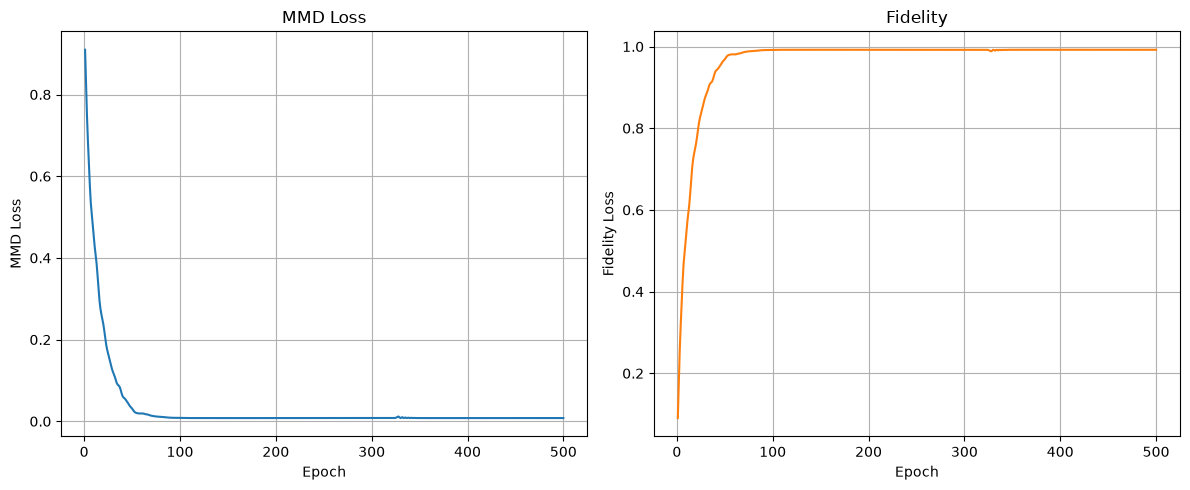


> Training finished.
Number of qubits: 7
Circuit depth (layers): 9
Number of parameters: 63
Best fidelity achieved: 0.99211473


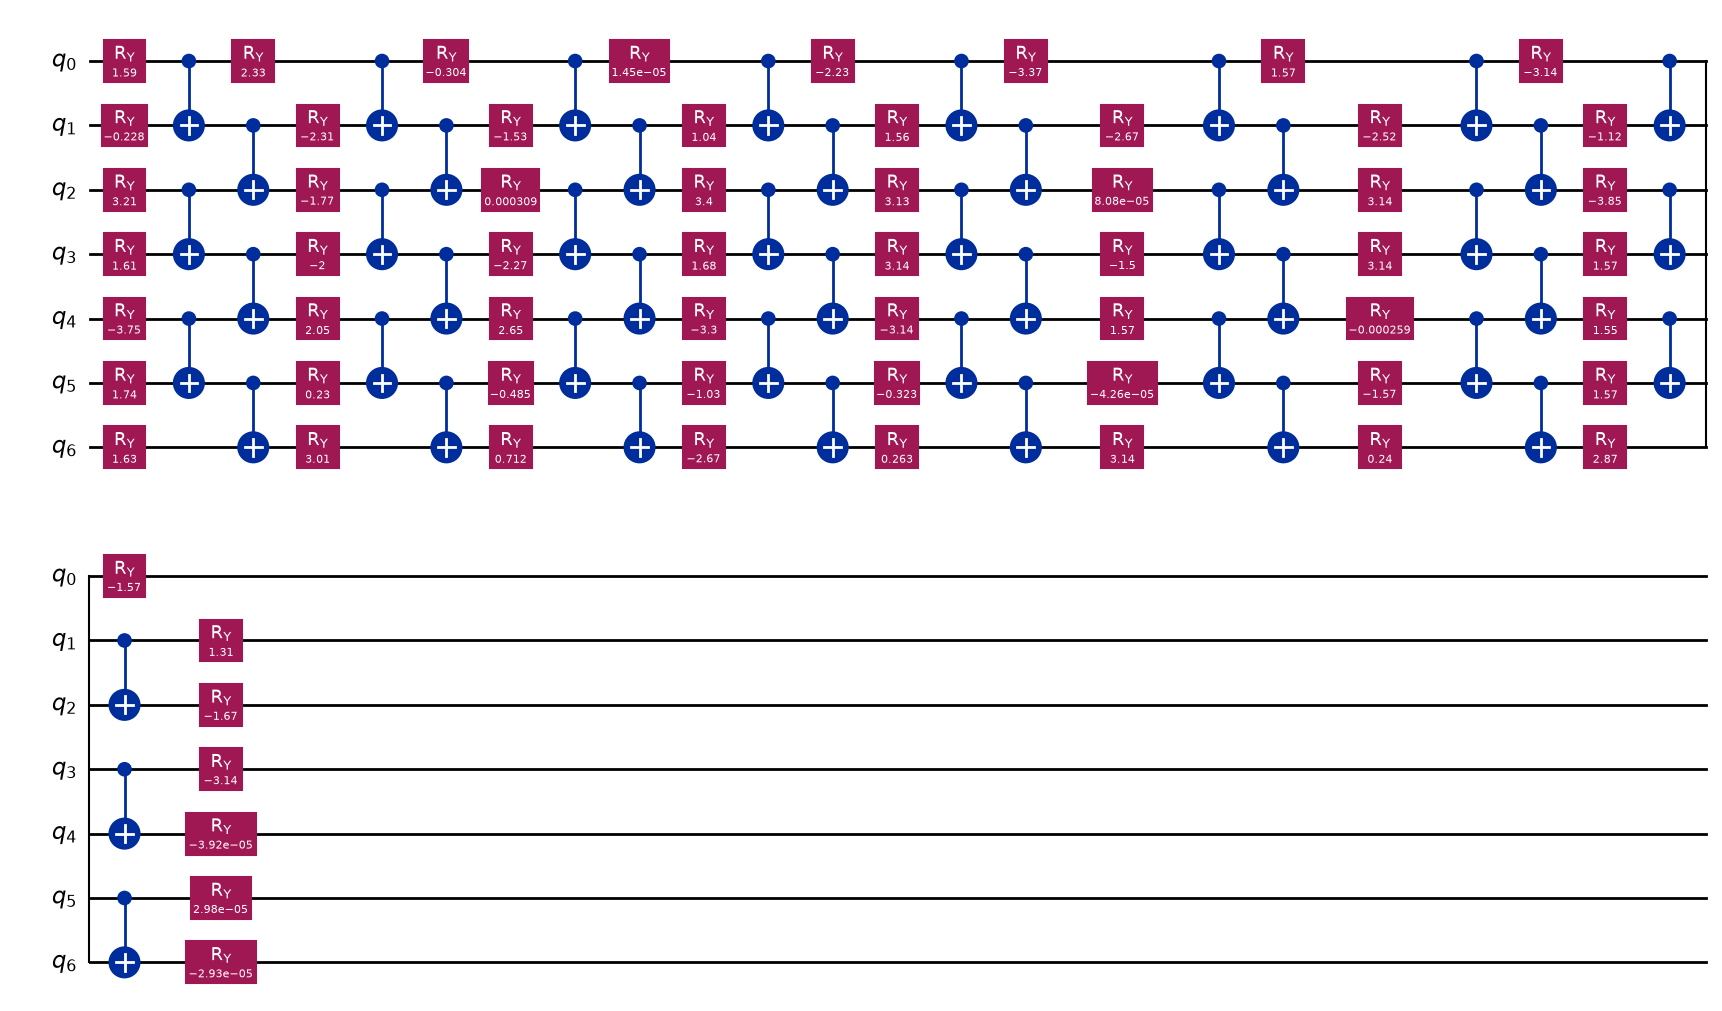


Data =  [[0 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 0 1 1]
 [0 1 0 0]
 [0 1 0 1]
 [0 1 1 0]
 [0 1 1 1]
 [1 0 0 0]
 [1 0 0 1]
 [1 0 1 0]
 [1 0 1 1]
 [1 1 0 0]
 [1 1 0 1]
 [1 1 1 0]
 [1 1 1 1]]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.99211473


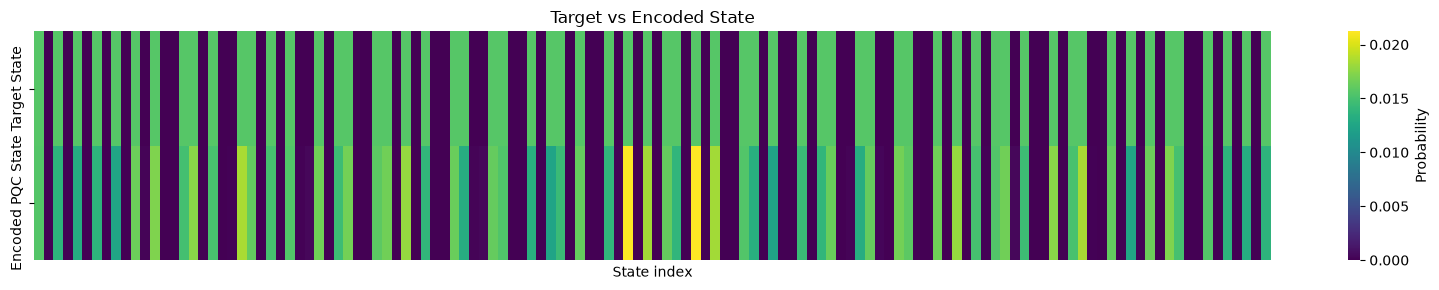

<Axes: title={'center': 'Target vs Encoded State'}, xlabel='State index'>

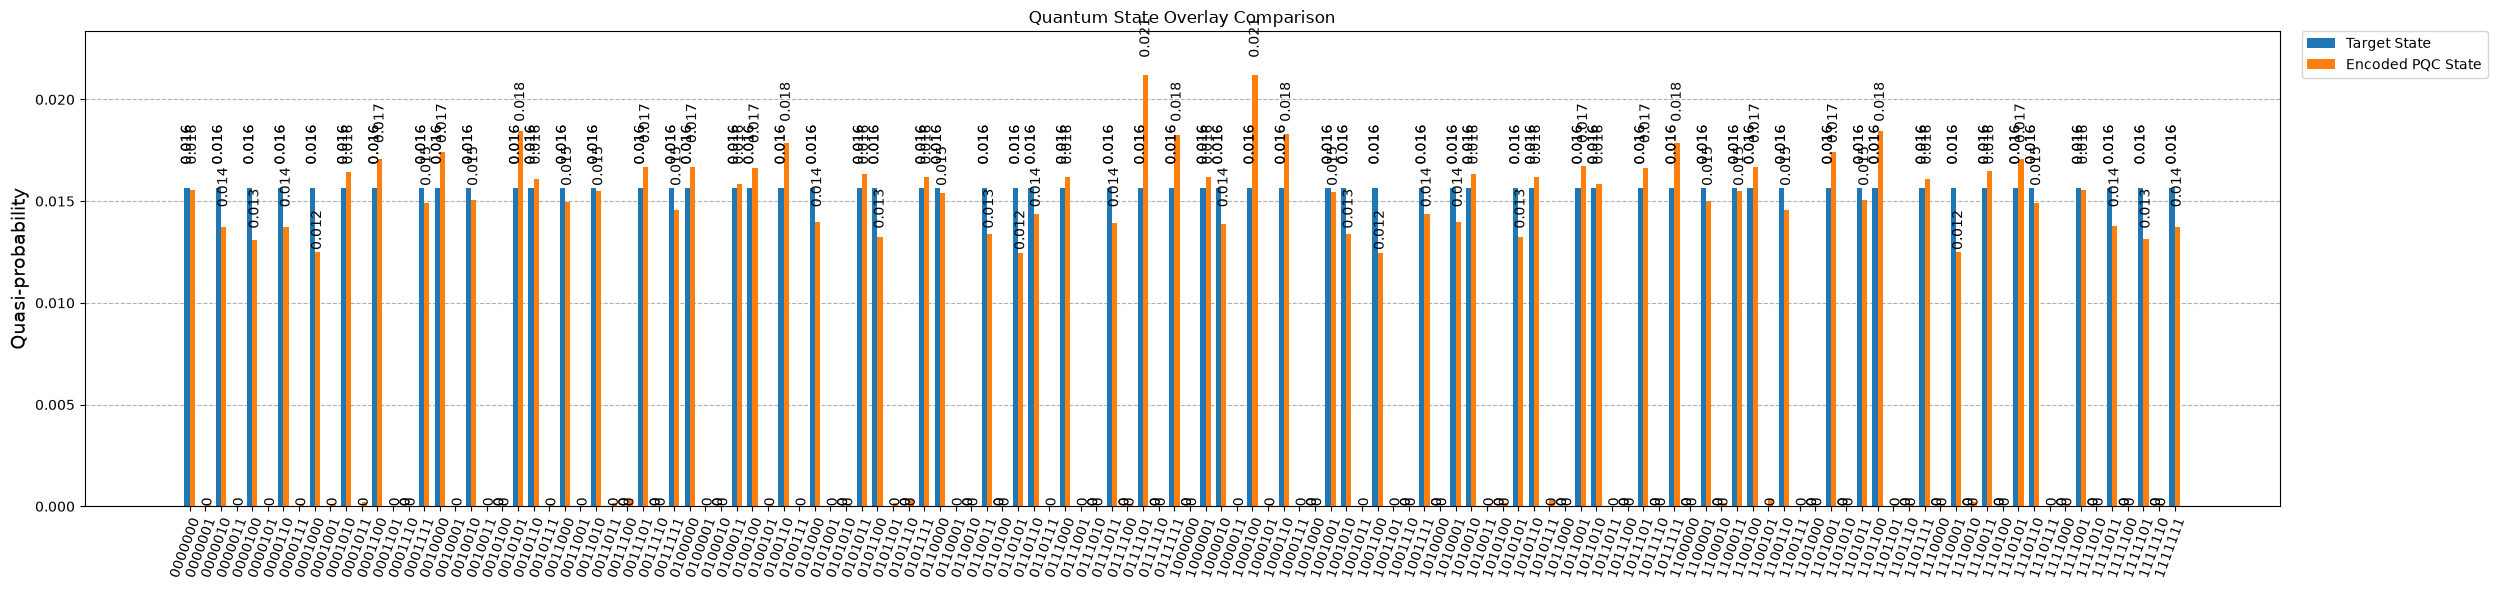


TARGET STATE
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.125                   +0.000                   
0                        1                        +0.125                   +0.000                   
0                        2                        +0.125                   +0.000                   
0                        3                        +0.125                   +0.000                   
1                        0                        +0.125                   +0.000                   
1                        1                        +0.125                   +0.000                   
1                        2                        +0.125                   +0.000                   
1                        3                        +0.000                   +0

<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.12478728126143093+0j)
|0000001> : (0.008426885717479633+0j)
|0000010> : (0.11724378812230513+0j)
|0000011> : (0.0051900064902402655+0j)
|0000100> : (0.11449309293397353+0j)
|0000101> : (0.0031666827813670033+0j)
|0000110> : (0.1172496636336123+0j)
|0000111> : (0.008607229377895414+0j)
|0001000> : (0.11175479713128952+0j)
|0001001> : (0.008560249423509988+0j)
|0001010> : (0.12828197122227464+0j)
|0001011> : (0.014428532550474155+0j)
|0001100> : (0.1307042729601117+0j)
|0001101> : (-0.004064958693028449+0j)
|0001110> : (0.0021890043444714622+0j)
|0001111> : (0.12215618171621412+0j)
|0010000> : (0.13195945581928675+0j)
|0010001> : (0.0015404813855248007+0j)
|0010010> : (0.12270339748579742+0j)
|0010011> : (0.0030087626866081504+0j)
|0010100> : (-0.011466788764703037+0j)
|0010101> : (0.13582865246328968+0j)
|0010110> : (0.12687954451651223+0j)
|0010111> : (-0.009046980962590791+0j)
|0011000> : (0.12240152920691492+0j)
|0011001> : (0.004507411323

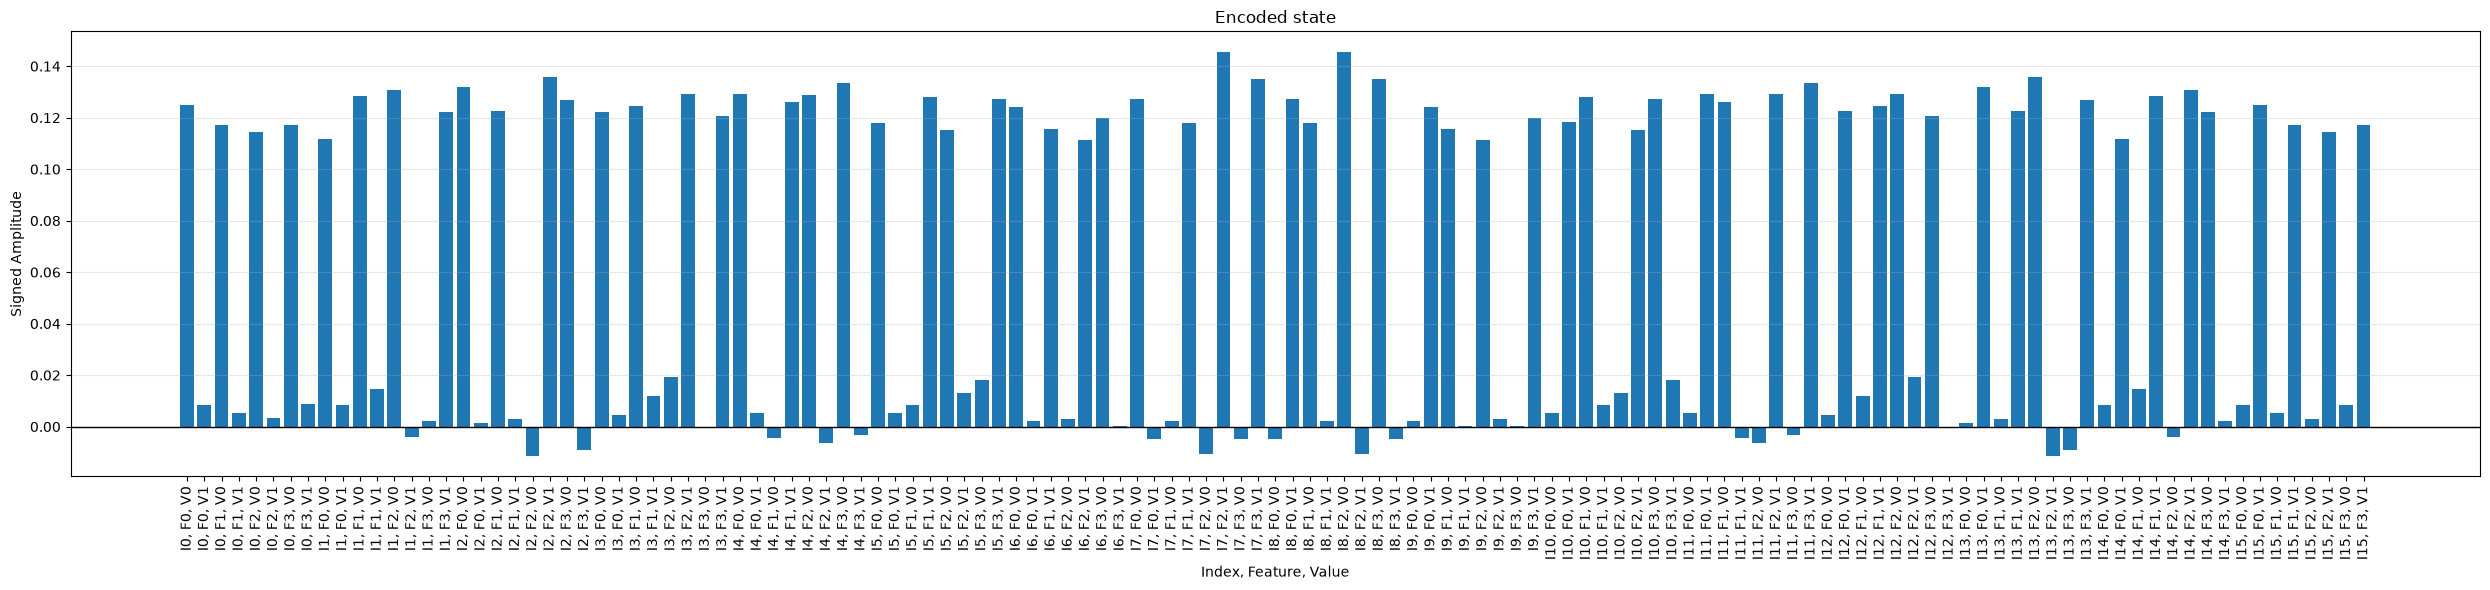


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


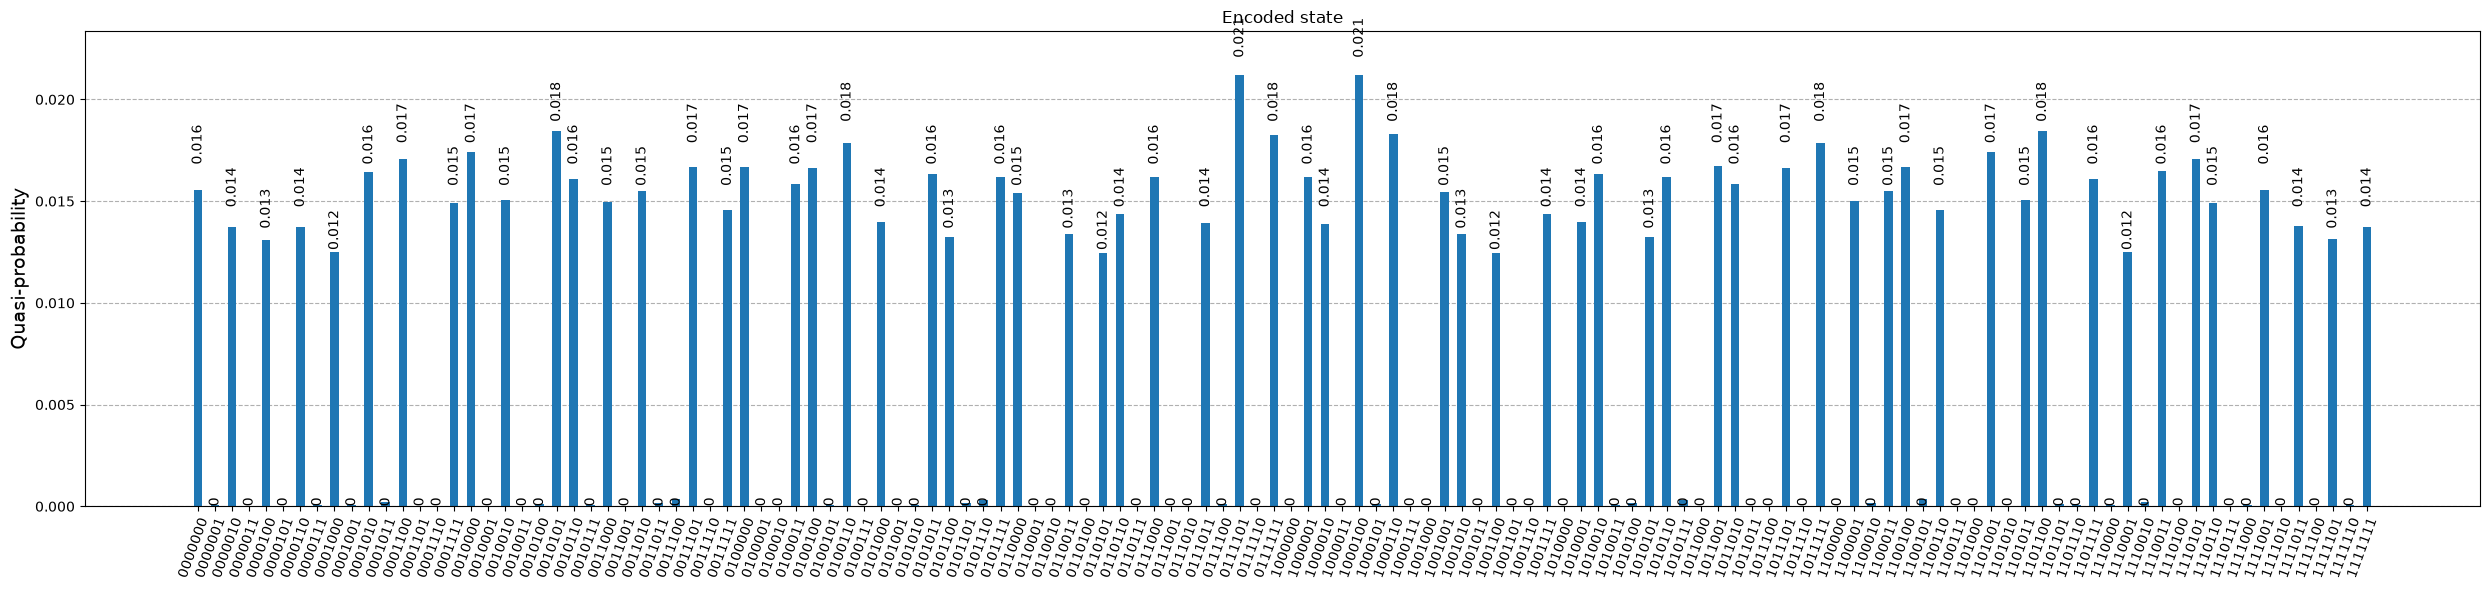

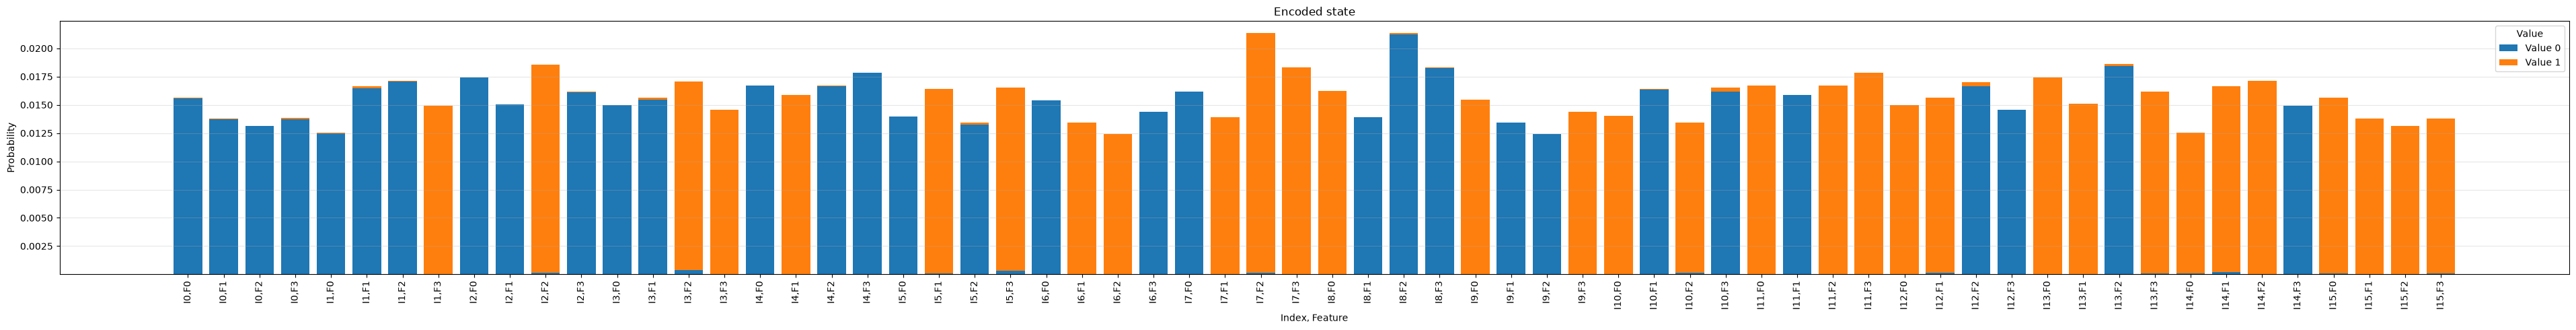


Encoded state
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.125                   +0.008                   
0                        1                        +0.117                   +0.005                   
0                        2                        +0.114                   +0.003                   
0                        3                        +0.117                   +0.009                   
1                        0                        +0.112                   +0.009                   
1                        1                        +0.128                   +0.014                   
1                        2                        +0.131                   -0.004                   
1                        3                        +0.002                   +

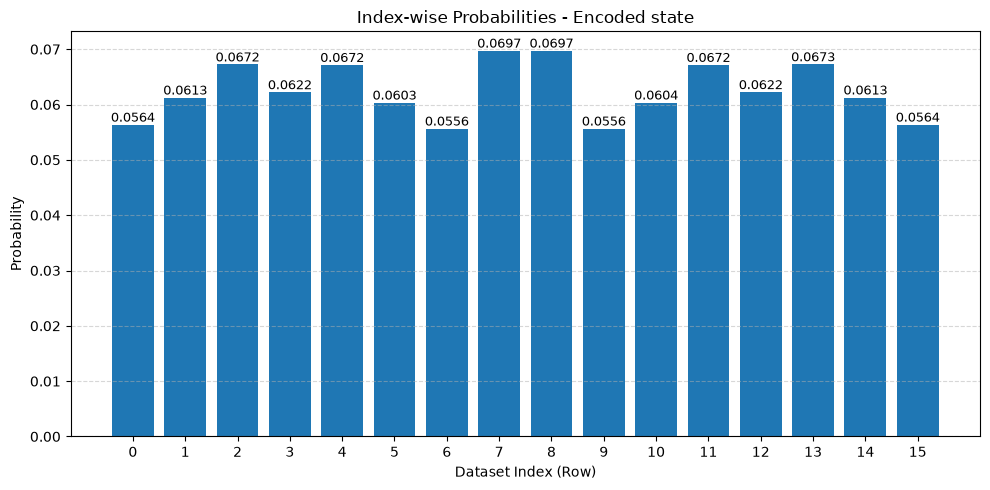

In [10]:
A_parameters, A_best_fidelity = encoder.generate_encoding(dataset, scheme="FRQI", depth=pqc_depth_for_dataset_encoder, epochs=epochs_dataset_encoder, learning_rate=learning_rate_dataset_encoder, loss_function_type="FIDELITY")

In [11]:
# SAVE THE BEST PERFORMING DATASET ENCODER

if A_best_fidelity > A_saved_best_fidelity:
    save_parameters(
        A_parameters,
        depth=pqc_depth_for_dataset_encoder, epochs=epochs_dataset_encoder, 
        learning_rate=learning_rate_dataset_encoder, fidelity=A_best_fidelity,
        scheme="FRQI", loss_function_type="FIDELITY"
    )

    print("New dataset encoder has better fidelity. Saved the new parameters.")

else:
    print(f"New dataset encoder did not improve fidelity {A_saved_best_fidelity}. Keeping the previous best parameters.")
    A_parameters = A_saved_parameters
    A_best_fidelity = A_saved_best_fidelity

print(f"Final best dataset encoder fidelity = {A_best_fidelity:.3f}")

New dataset encoder did not improve fidelity 0.9921147297970886. Keeping the previous best parameters.
Final best dataset encoder fidelity = 0.992



> Preparing query target state....

Number of feature-index qubits: 2
Number of intensity qubits: 1
Total number of qubits: 3
Total number of states: 8

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 7

> Starting training....

Number of parameters = 9

> Using adam optimization....
Epoch 1 - Loss 0.863516233878385 - Fidelity 0.136483766121615
Epoch 2 - Loss 0.7872190347224719 - Fidelity 0.21278096527752804
Epoch 3 - Loss 0.7016313677329188 - Fidelity 0.2983686322670812
Epoch 4 - Loss 0.599003296036326 - Fidelity 0.40099670396367404
Epoch 5 - Loss 0.48030623527812477 - Fidelity 0.5196937647218752
Epoch 6 - Loss 0.3583450663022901 - Fidelity 0.6416549336977099
Epoch 7 - Loss 0.25297815918308475 - Fidelity 0.7470218408169153
Epoch 8 - Loss 0.1834152973537514 - Fidelity 0.8165847026462486
Epoch 9 - Loss 0.1507797606321476 - Fidelity 0.8492202393678524
Epoch 10 - Loss 0.13332693108124916 - Fidelity 0.8666730689187508
Epoch 11 - Loss 0.11760248793815198 - Fidelity 0.882397512061848
Epoch 12 - Loss 0.10446868903372697 - Fidelity 0.895531310966273
Epoch 13 - Loss 0.09808873737963253 - Fidelity 0.9019112626203675
Epoch 14 - Loss 0.09890661767096864 - F

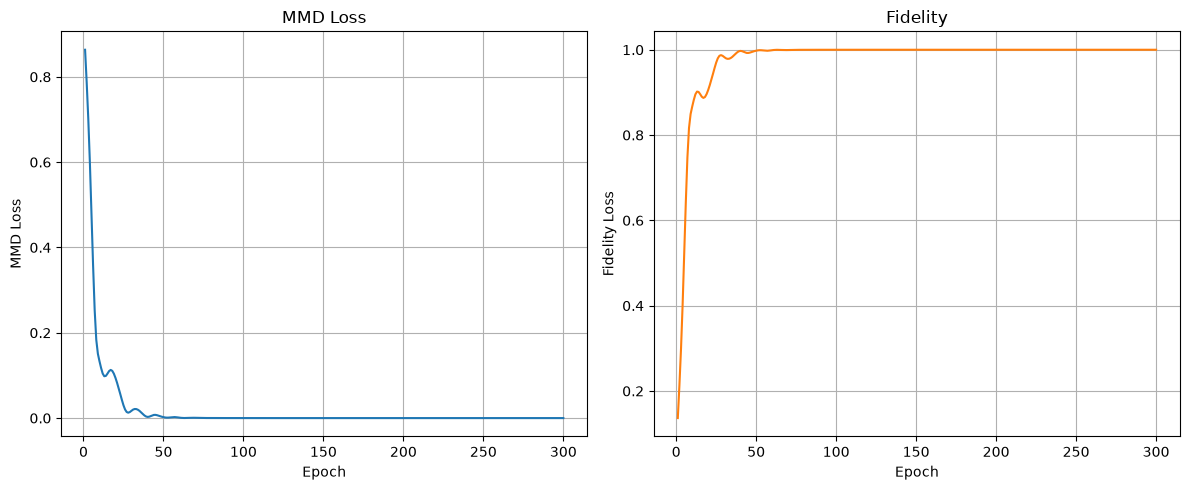


> Training finished.
Number of qubits: 3
Circuit depth (layers): 3
Number of parameters: 9
Best fidelity achieved: 0.99999979


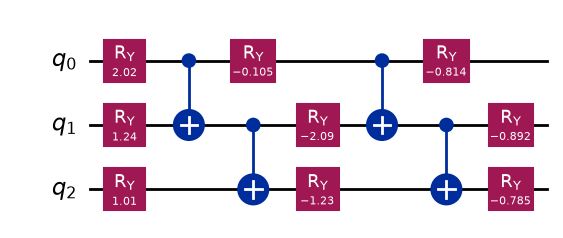


Data =  [0 1 1 1]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.99999979


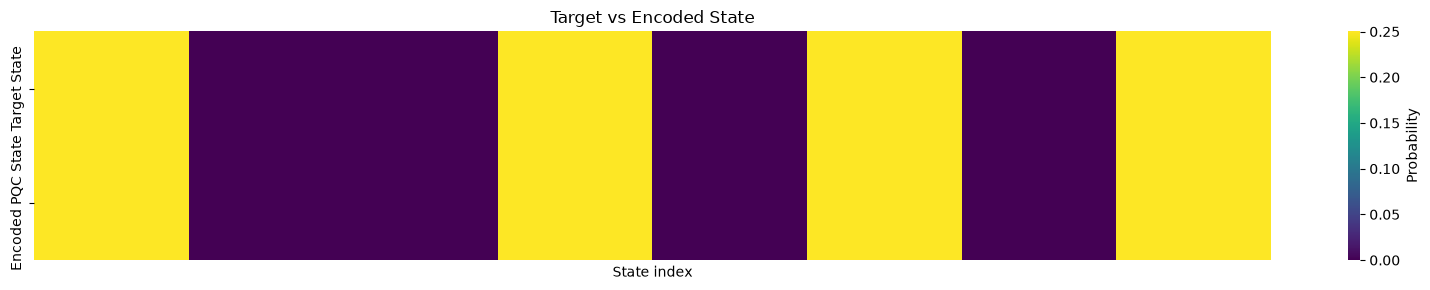

<Axes: title={'center': 'Target vs Encoded State'}, xlabel='State index'>

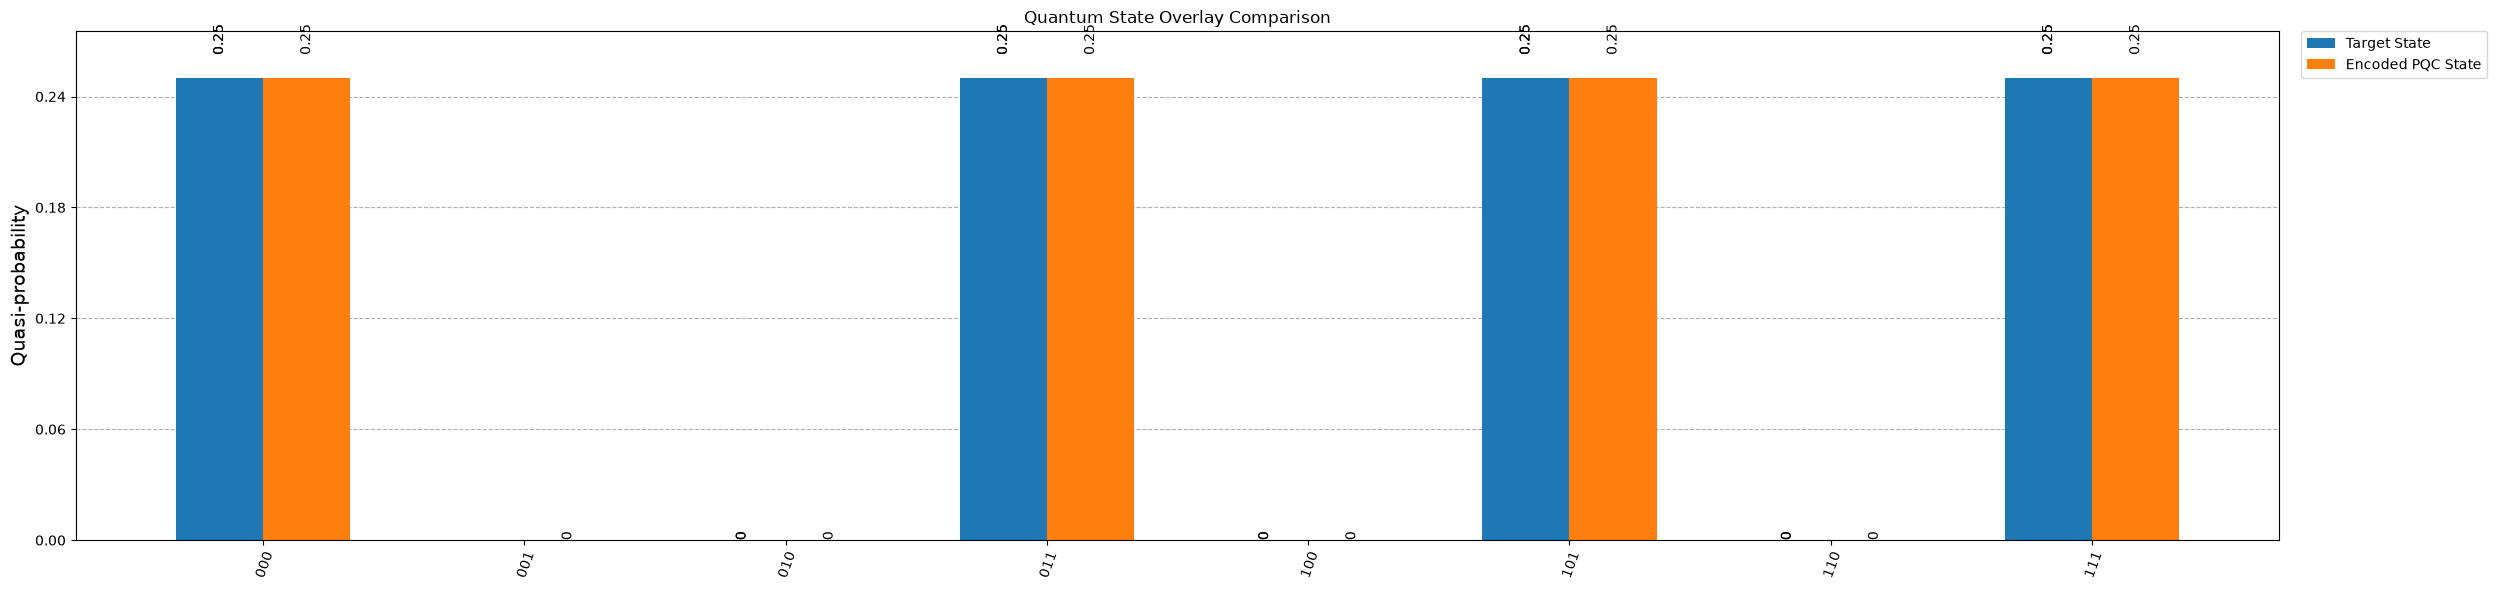


TARGET STATE
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        +0.500                   +0.000                   
1                        +0.000                   +0.500                   
2                        +0.000                   +0.500                   
3                        +0.000                   +0.500                   

ENCODED STATE
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        +0.500                   +0.000                   
1                        +0.000                   +0.500                   
2                        +0.000                   +0.500                   
3                        +0.000                   +0.500                   

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000> : (0.5002369201795601+0j)
|010> : (8.319396619947892e-05+0j)
|011> : (0.49981416990493005+0j)
|100> : (-6.461954350926567e-05+0j)
|101> : (0.49974479701196506+0j)
|110> : (-6.274886739393449e-05+0j)
|111> : (0.5002039004454942+0j)


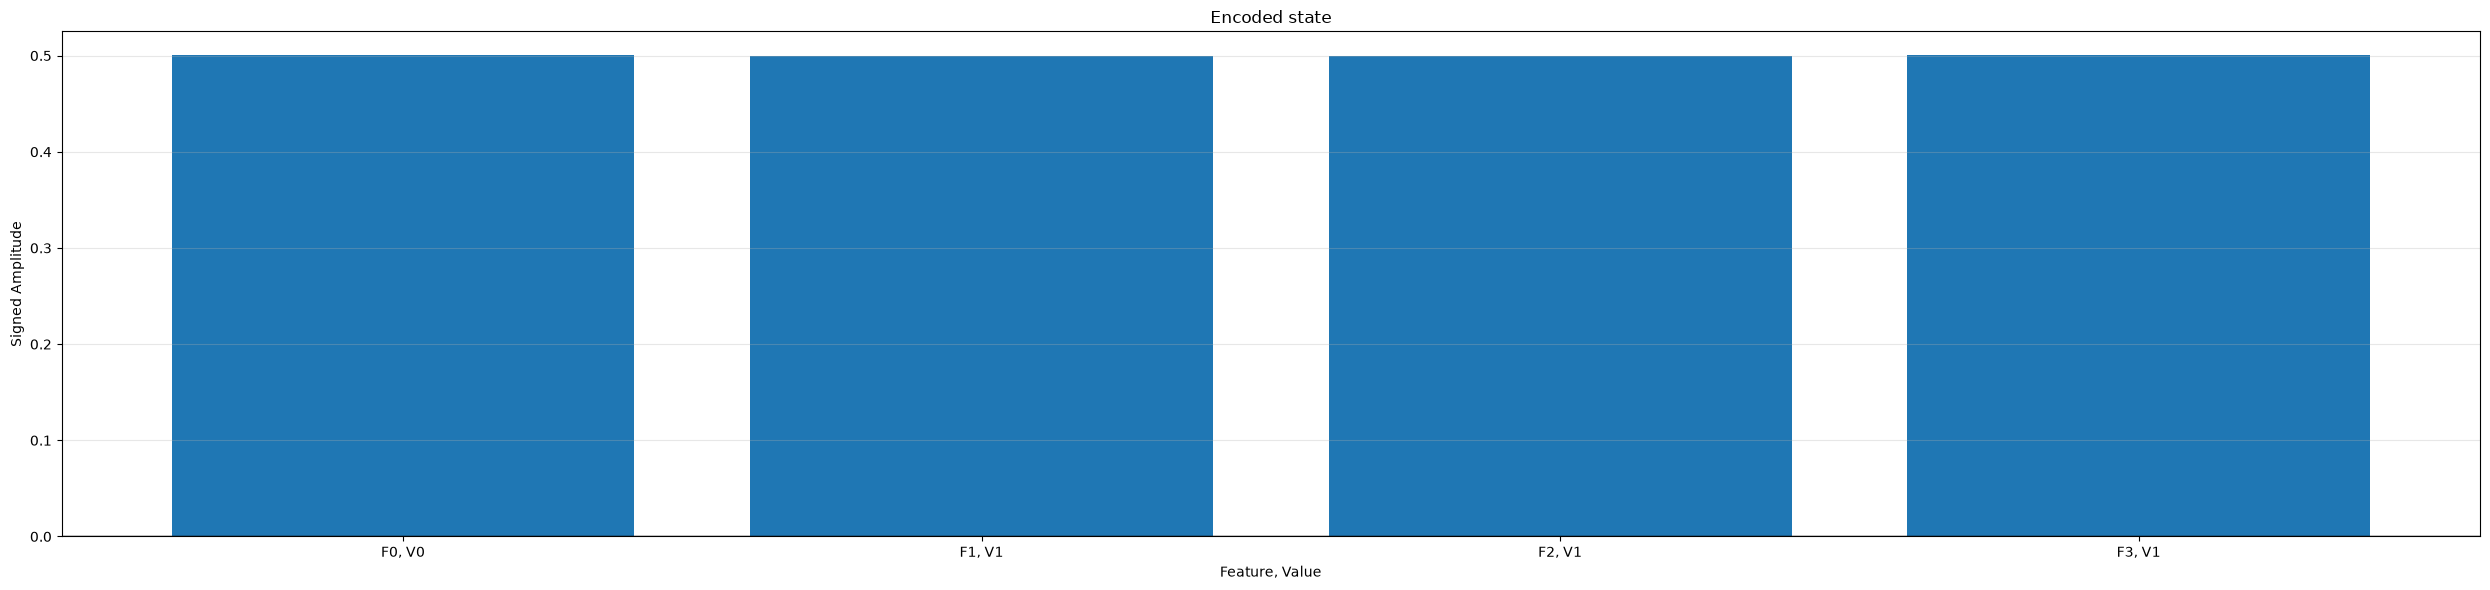


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


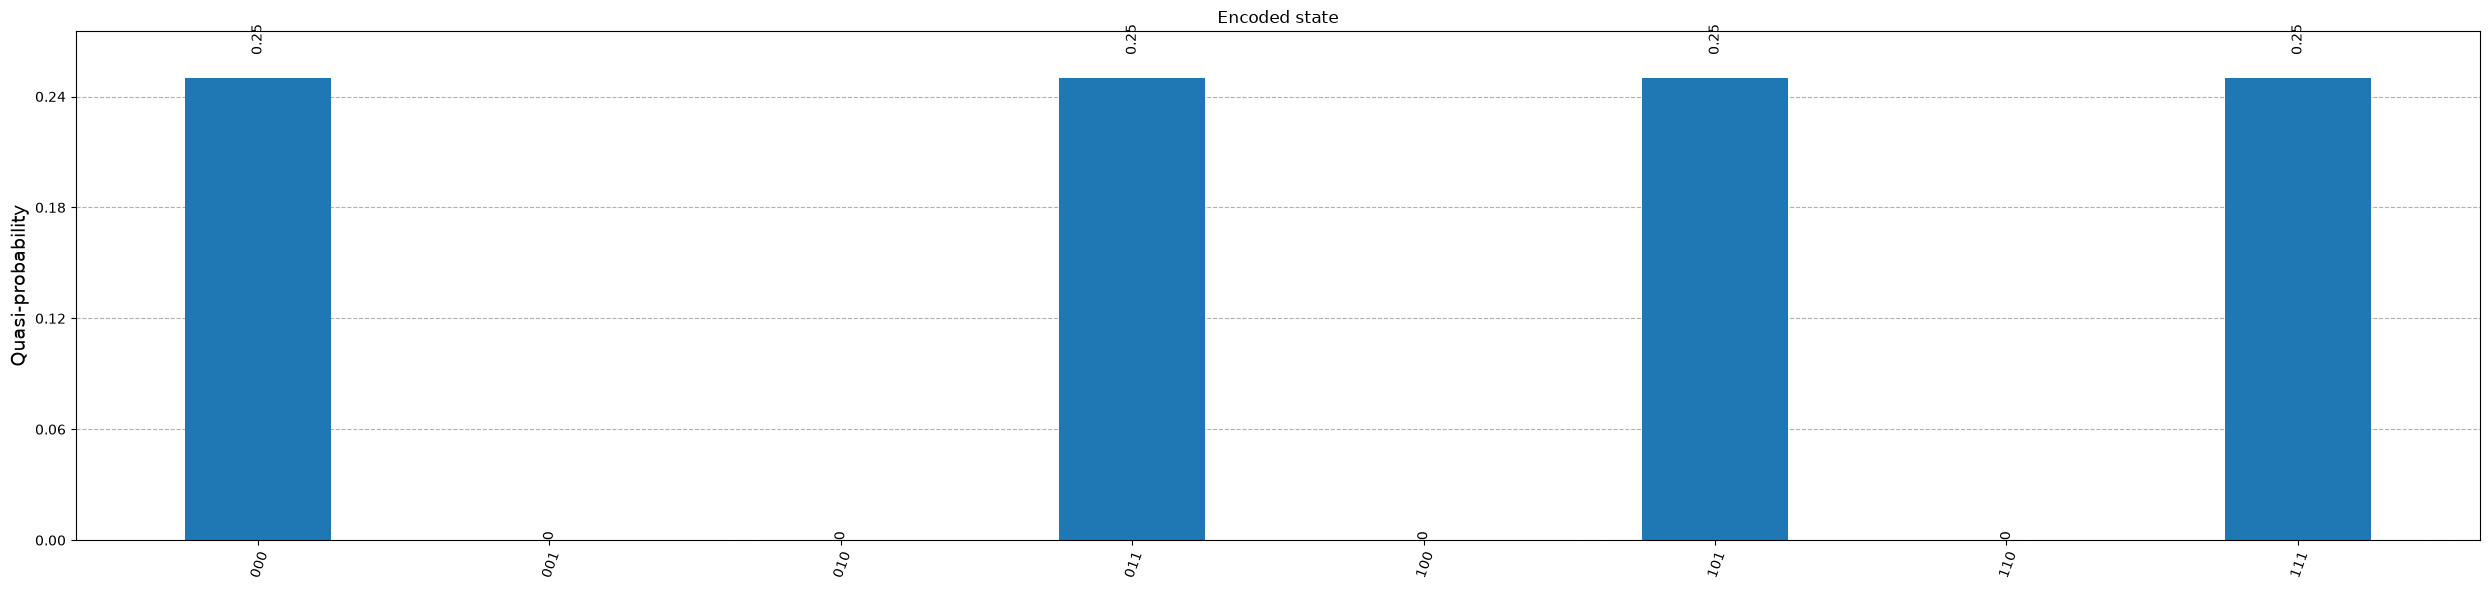

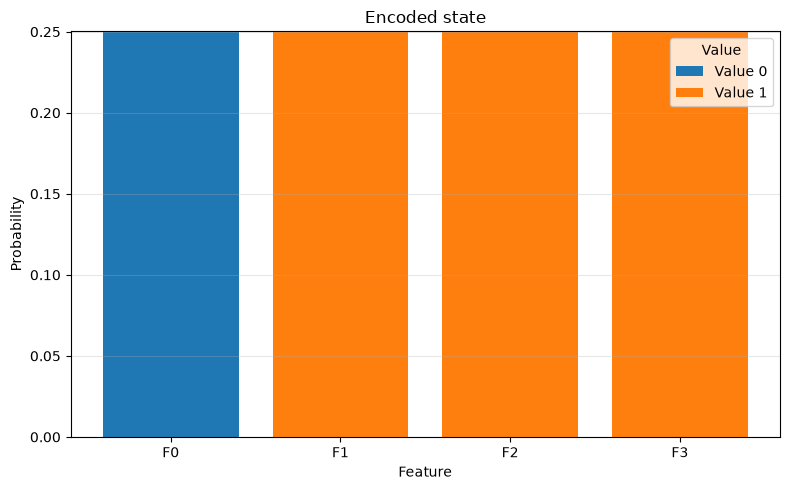


Encoded state
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        +0.500                   +0.000                   
1                        +0.000                   +0.500                   
2                        +0.000                   +0.500                   
3                        +0.000                   +0.500                   


In [12]:
B_parameters_frqi_fidelity, _ = encoder.generate_encoding(query, scheme="FRQI", depth=pqc_depth_for_query_encoder, epochs=300, learning_rate=0.1, loss_function_type="FIDELITY")

## <u>**U operation**</u>

U = (B† ⊗ I_I) A

In [13]:
n_index_q = math.ceil(math.log2(len(dataset)))
n_feature_q = math.ceil(math.log2(len(dataset[0])))

max_value = int(np.max(dataset))
n_value_q = max(1, math.ceil(math.log2(max_value + 1)))
print("Index qubits = ", n_index_q)
print("Feature qubits = ", n_feature_q)
print("Value qubits = ", n_value_q)

Index qubits =  4
Feature qubits =  2
Value qubits =  1


In [14]:
A = encoder.pqc(A_parameters, depth=pqc_depth_for_dataset_encoder, n_qubits=(n_index_q + n_feature_q + n_value_q))

In [15]:
B = encoder.pqc(B_parameters_frqi_fidelity, depth=pqc_depth_for_query_encoder, n_qubits=(n_value_q + n_feature_q))


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (1+0j)


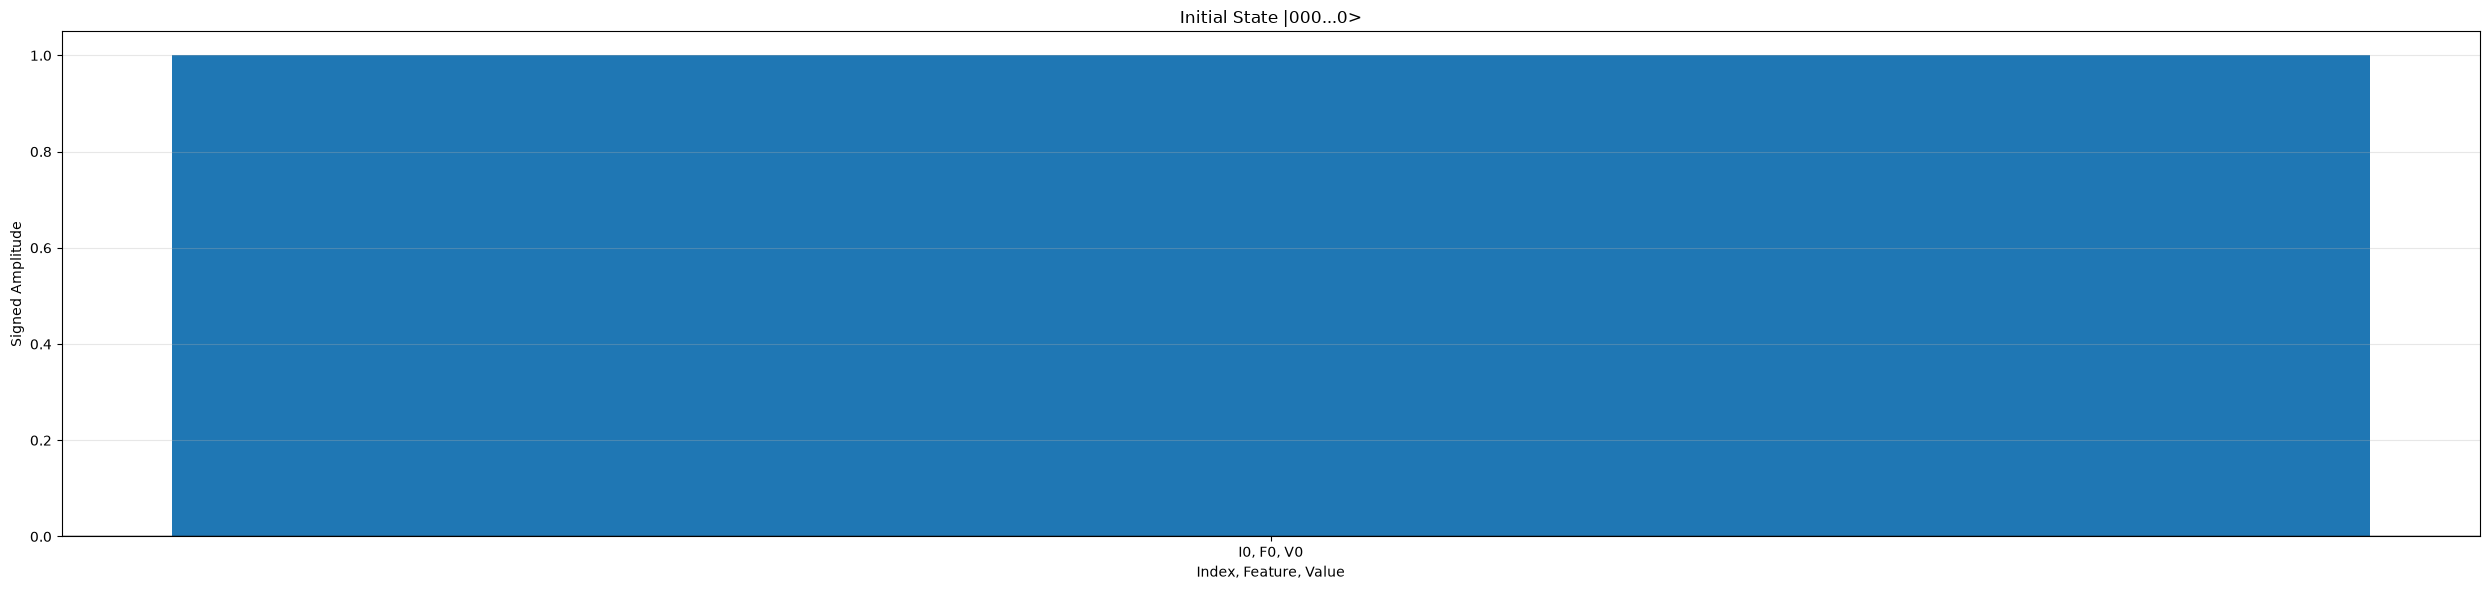


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


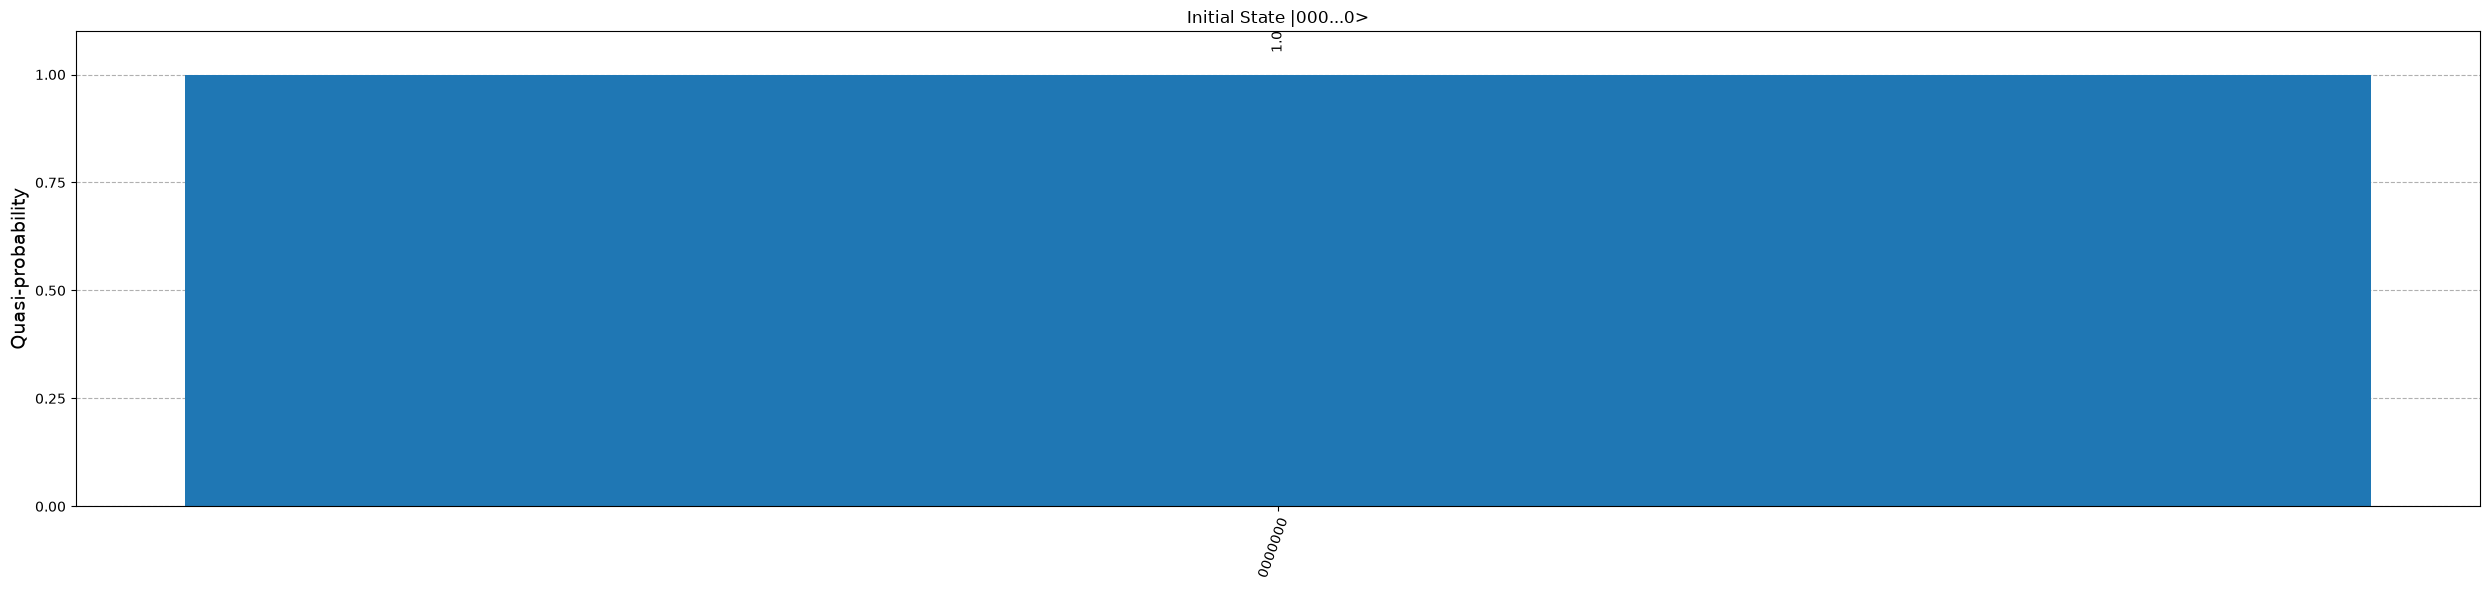

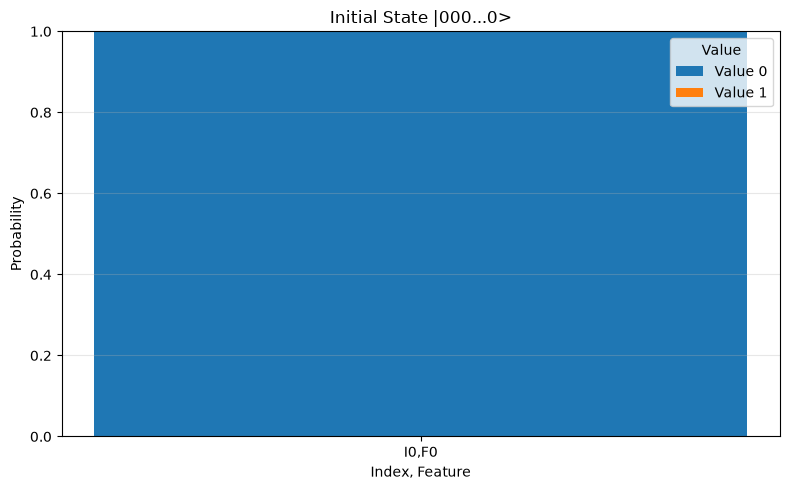


Initial State |000...0>
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +1.000                   +0.000                   


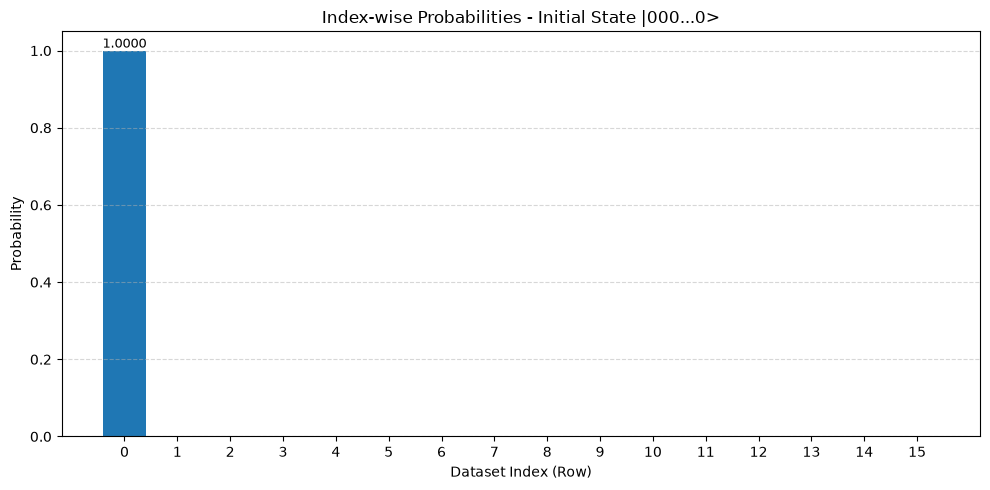

In [16]:
value_reg = QuantumRegister(n_value_q, "Value")
feature_reg = QuantumRegister(n_feature_q, "Feature")
index_reg = QuantumRegister(n_index_q, "Index")
qc = QuantumCircuit(value_reg, feature_reg, index_reg)

initial_state = Statevector.from_instruction(qc)
state_analysis(initial_state, "Initial State |000...0>", n_value_q, n_feature_q, n_index_q)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.12478728126143093+0j)
|0000001> : (0.008426885717479633+0j)
|0000010> : (0.11724378812230513+0j)
|0000011> : (0.0051900064902402655+0j)
|0000100> : (0.11449309293397353+0j)
|0000101> : (0.0031666827813670033+0j)
|0000110> : (0.1172496636336123+0j)
|0000111> : (0.008607229377895414+0j)
|0001000> : (0.11175479713128952+0j)
|0001001> : (0.008560249423509988+0j)
|0001010> : (0.12828197122227464+0j)
|0001011> : (0.014428532550474155+0j)
|0001100> : (0.1307042729601117+0j)
|0001101> : (-0.004064958693028449+0j)
|0001110> : (0.0021890043444714622+0j)
|0001111> : (0.12215618171621412+0j)
|0010000> : (0.13195945581928675+0j)
|0010001> : (0.0015404813855248007+0j)
|0010010> : (0.12270339748579742+0j)
|0010011> : (0.0030087626866081504+0j)
|0010100> : (-0.011466788764703037+0j)
|0010101> : (0.13582865246328968+0j)
|0010110> : (0.12687954451651223+0j)
|0010111> : (-0.009046980962590791+0j)
|0011000> : (0.12240152920691492+0j)
|0011001> : (0.004507411323

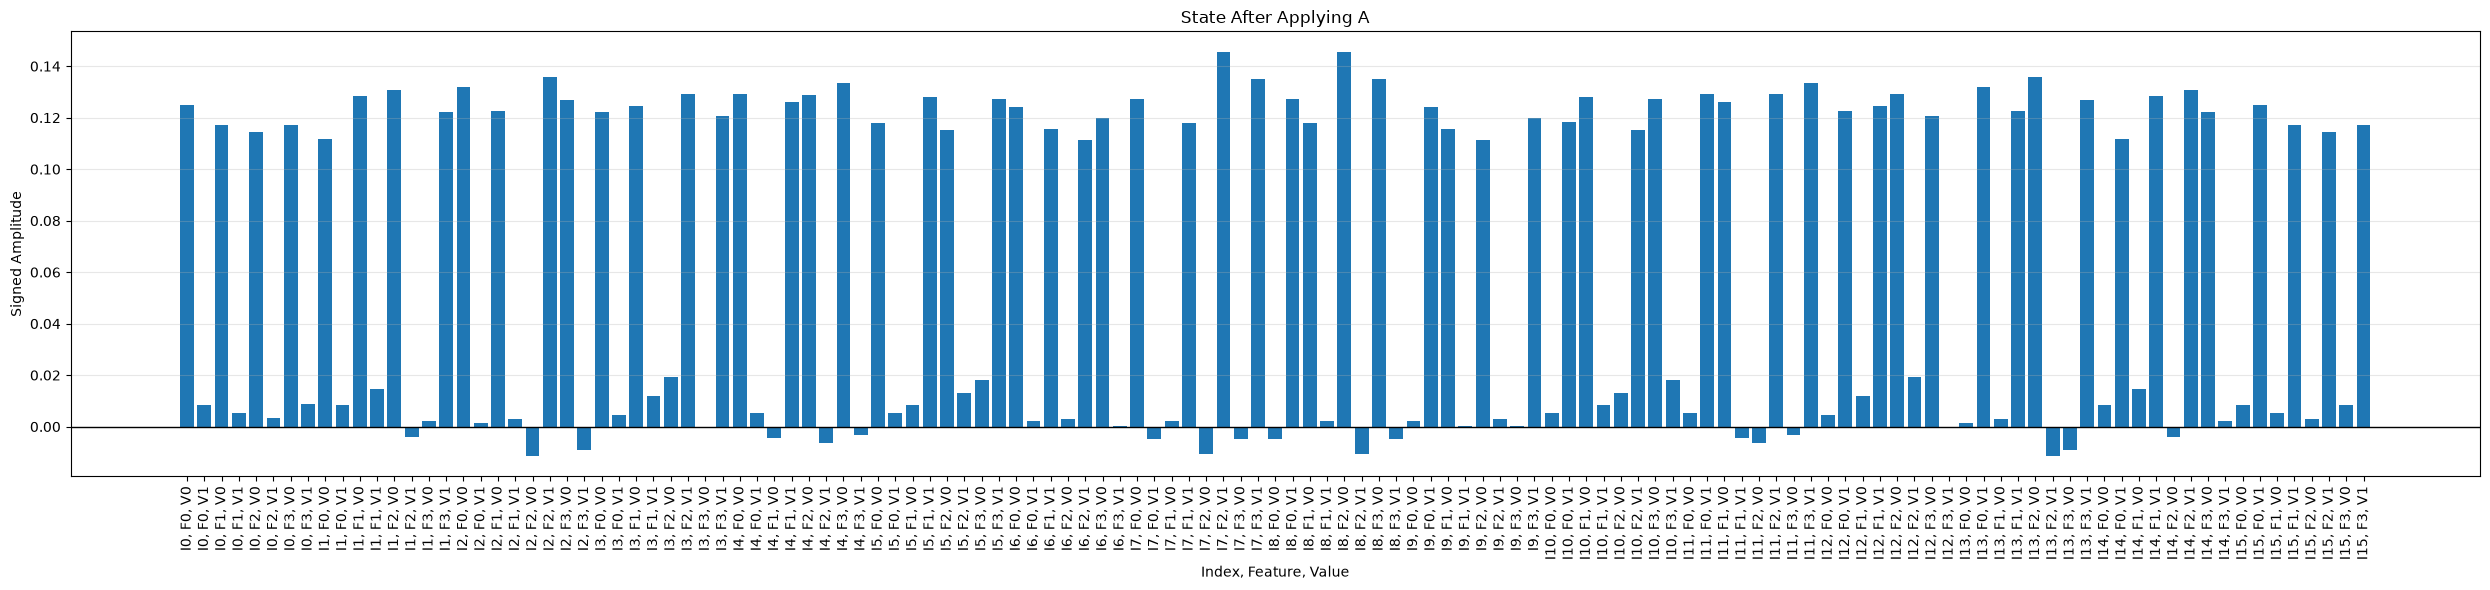


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


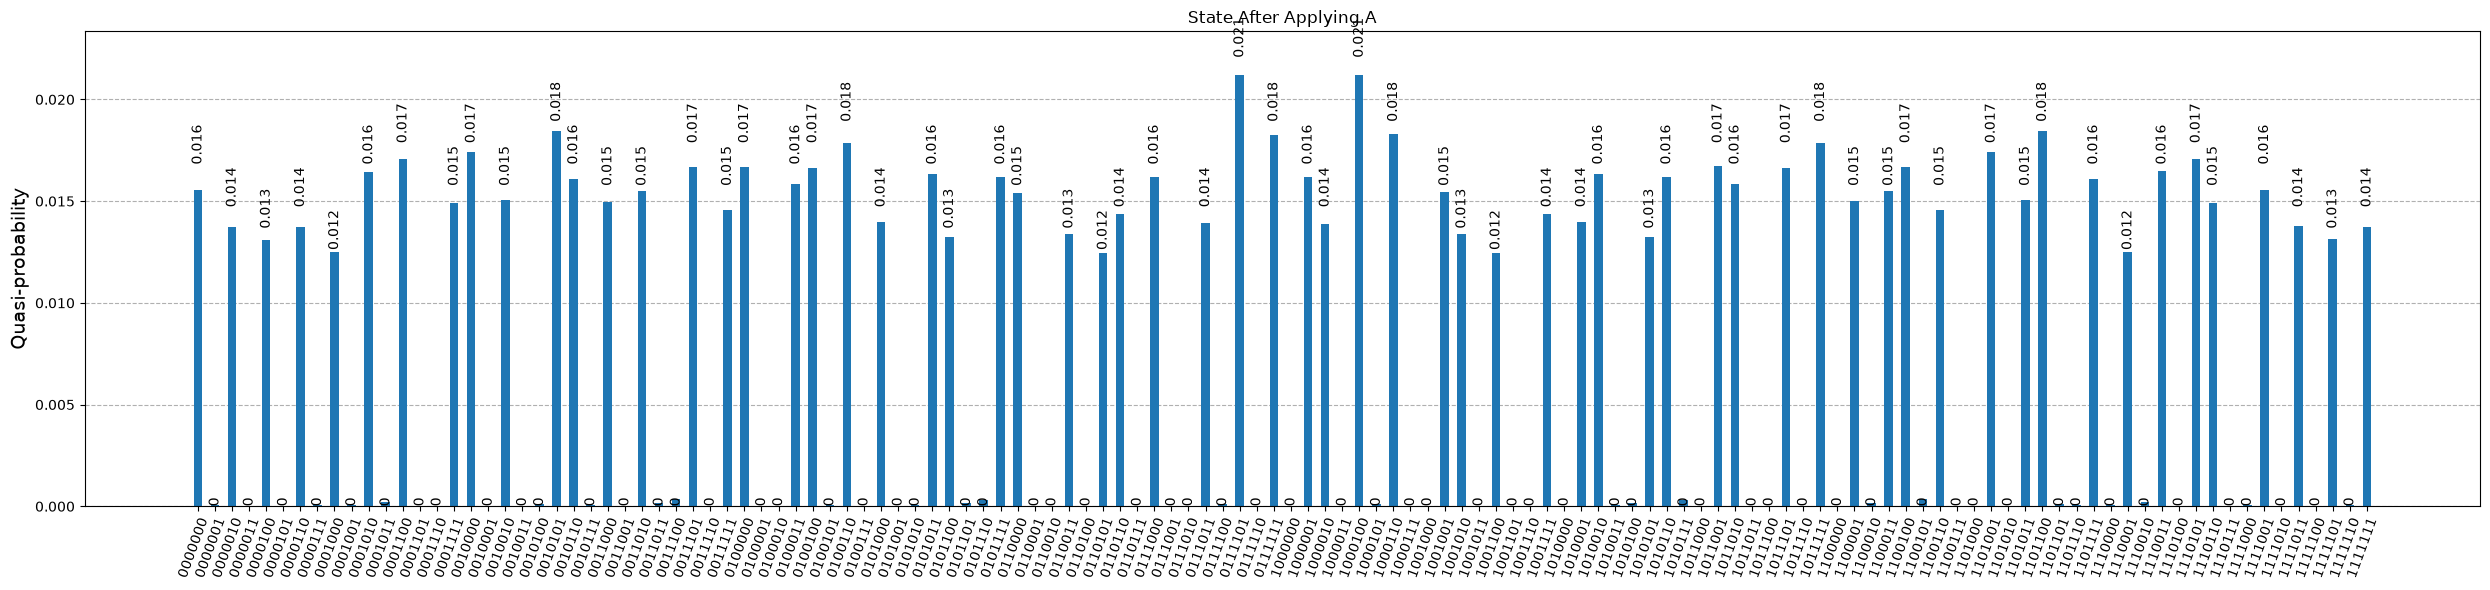

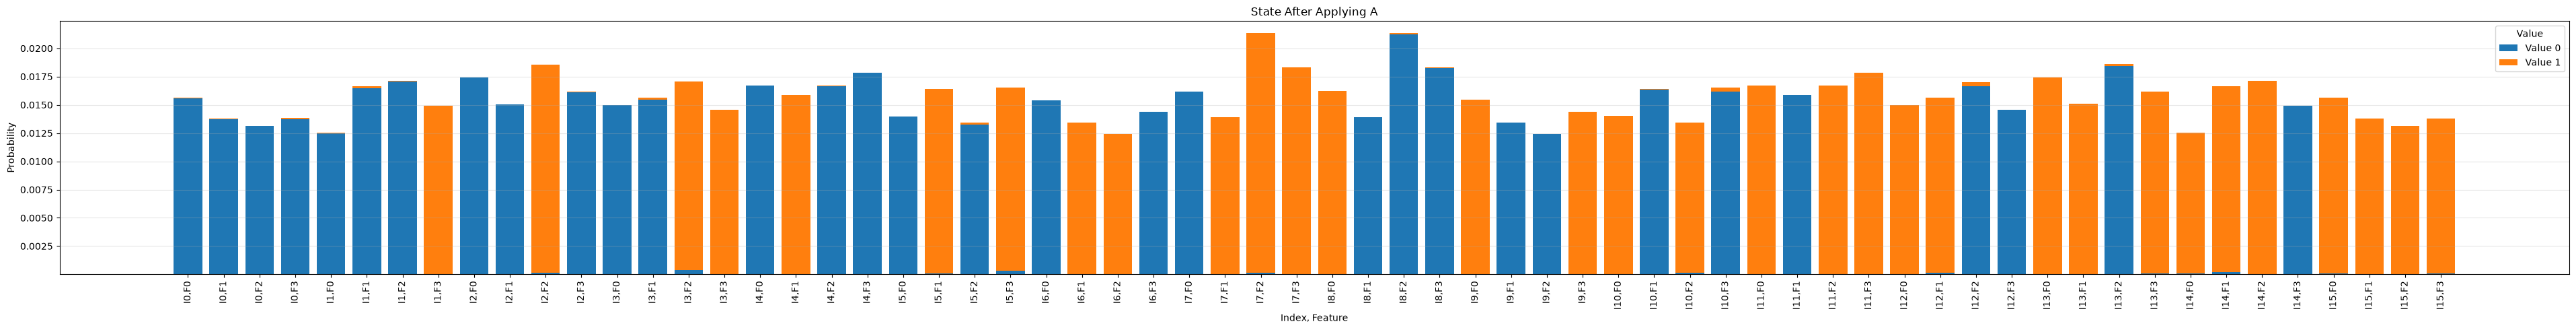


State After Applying A
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.125                   +0.008                   
0                        1                        +0.117                   +0.005                   
0                        2                        +0.114                   +0.003                   
0                        3                        +0.117                   +0.009                   
1                        0                        +0.112                   +0.009                   
1                        1                        +0.128                   +0.014                   
1                        2                        +0.131                   -0.004                   
1                        3                        +0.002           

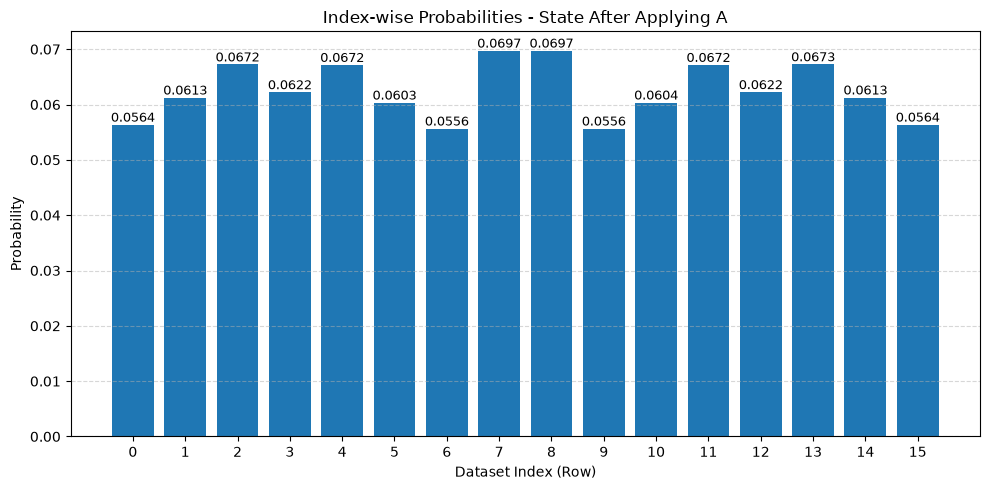

In [17]:
qc.compose(A, inplace=True)
qc.barrier()

state_after_A = Statevector.from_instruction(qc)
state_analysis(state_after_A, "State After Applying A", n_value_q, n_feature_q, n_index_q)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.07090020811668361+0j)
|0000001> : (0.07819993319383609+0j)
|0000010> : (0.06711671722821226+0j)
|0000011> : (-0.19207614028612743+0j)
|0000100> : (-0.039845626567146686+0j)
|0000101> : (0.04718218255248071+0j)
|0000110> : (1.2290531005143921e-05+0j)
|0000111> : (-0.0015444410371535855+0j)
|0001000> : (0.12218916995057615+0j)
|0001001> : (0.06996759741740519+0j)
|0001010> : (0.0257277972690492+0j)
|0001011> : (-0.11387033810944598+0j)
|0001100> : (-0.04312141815267681+0j)
|0001101> : (0.12854951258234343+0j)
|0001110> : (-0.055251922269341606+0j)
|0001111> : (0.07976637372244073+0j)
|0010000> : (0.13087214029725133+0j)
|0010001> : (0.04792105911964145+0j)
|0010010> : (0.058804921251110746+0j)
|0010011> : (-0.12010815898990022+0j)
|0010100> : (-0.08301849175971913+0j)
|0010101> : (0.025957144473622126+0j)
|0010110> : (0.042440140172171084+0j)
|0010111> : (-0.143412279016705+0j)
|0011000> : (0.19209095448071822+0j)
|0011001> : (0.03905337744621

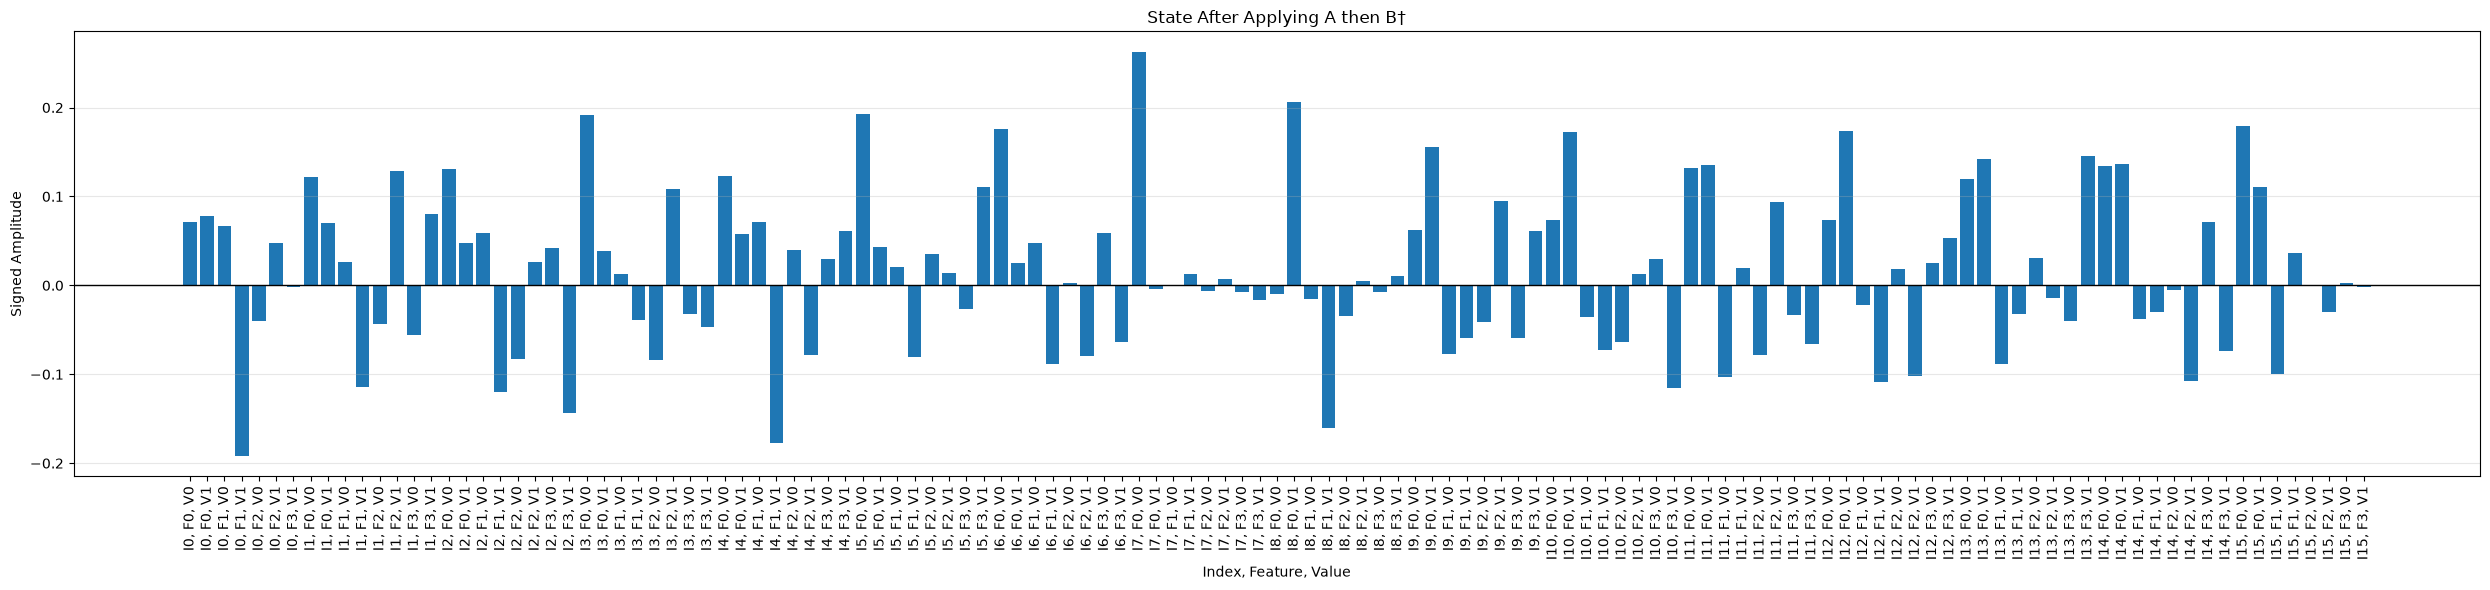


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


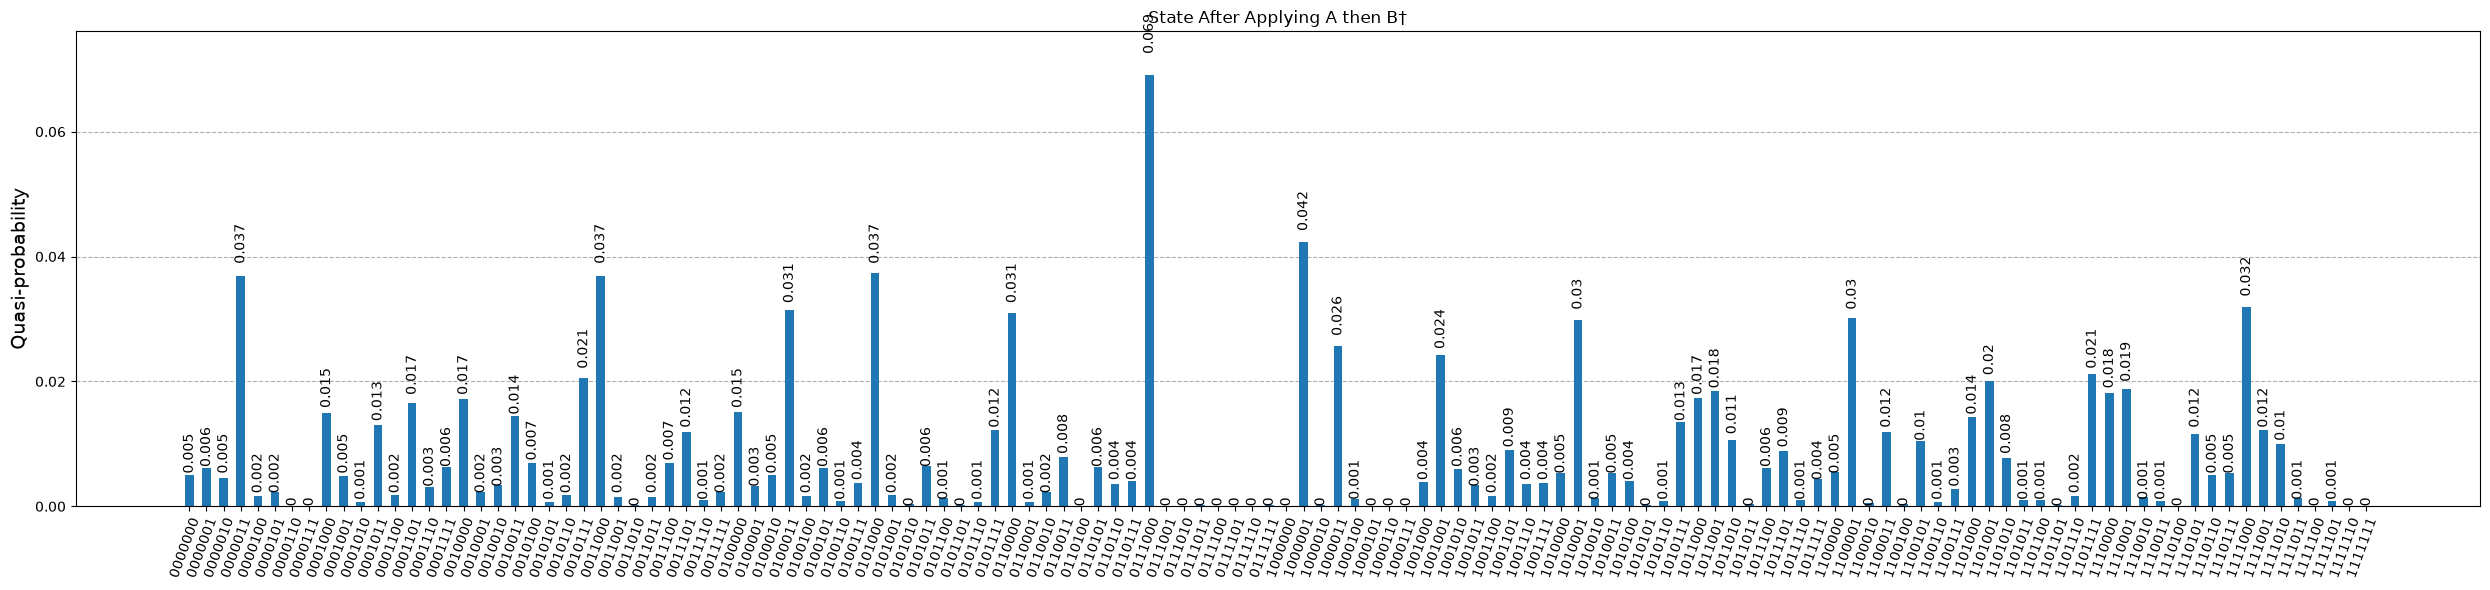

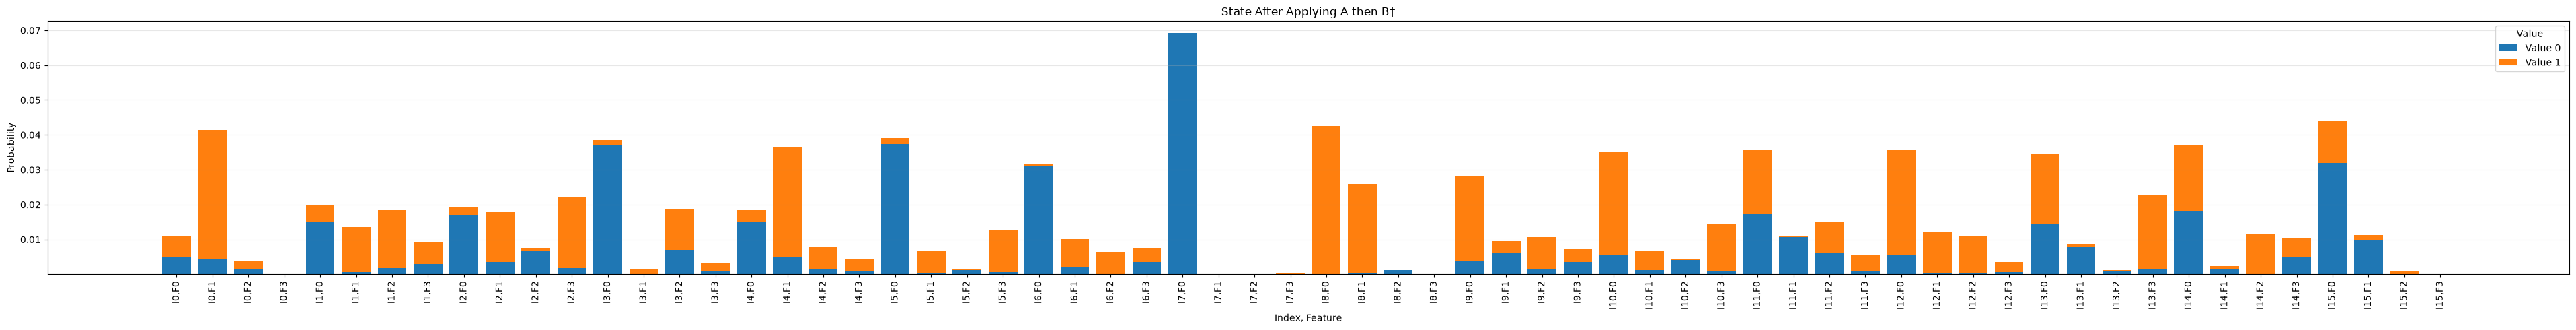


State After Applying A then B†
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.071                   +0.078                   
0                        1                        +0.067                   -0.192                   
0                        2                        -0.040                   +0.047                   
0                        3                        +0.000                   -0.002                   
1                        0                        +0.122                   +0.070                   
1                        1                        +0.026                   -0.114                   
1                        2                        -0.043                   +0.129                   
1                        3                        -0.055   

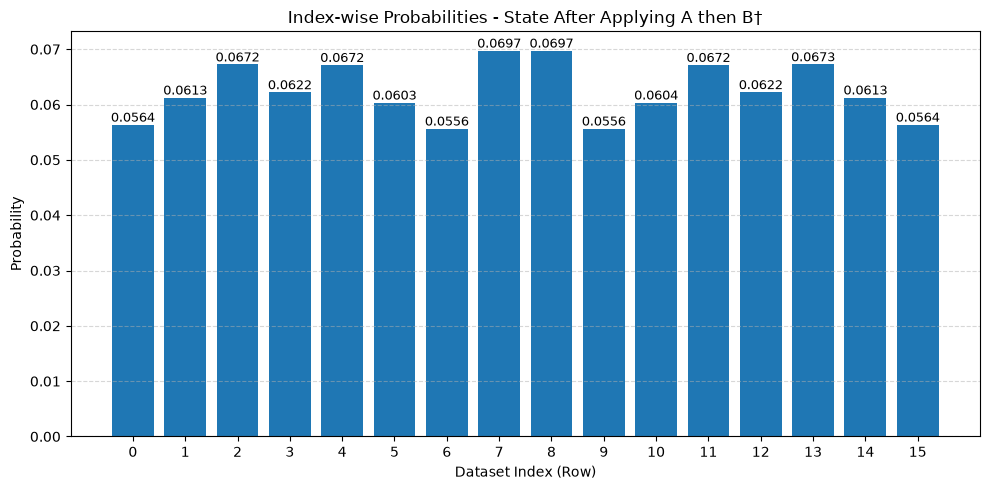

In [18]:
qc.compose(B.inverse(), qubits=range(n_feature_q + n_value_q), inplace=True)
qc.barrier()

state_after_B_inverse = Statevector.from_instruction(qc)
state_analysis(state_after_B_inverse, "State After Applying A then B†", n_value_q, n_feature_q, n_index_q)

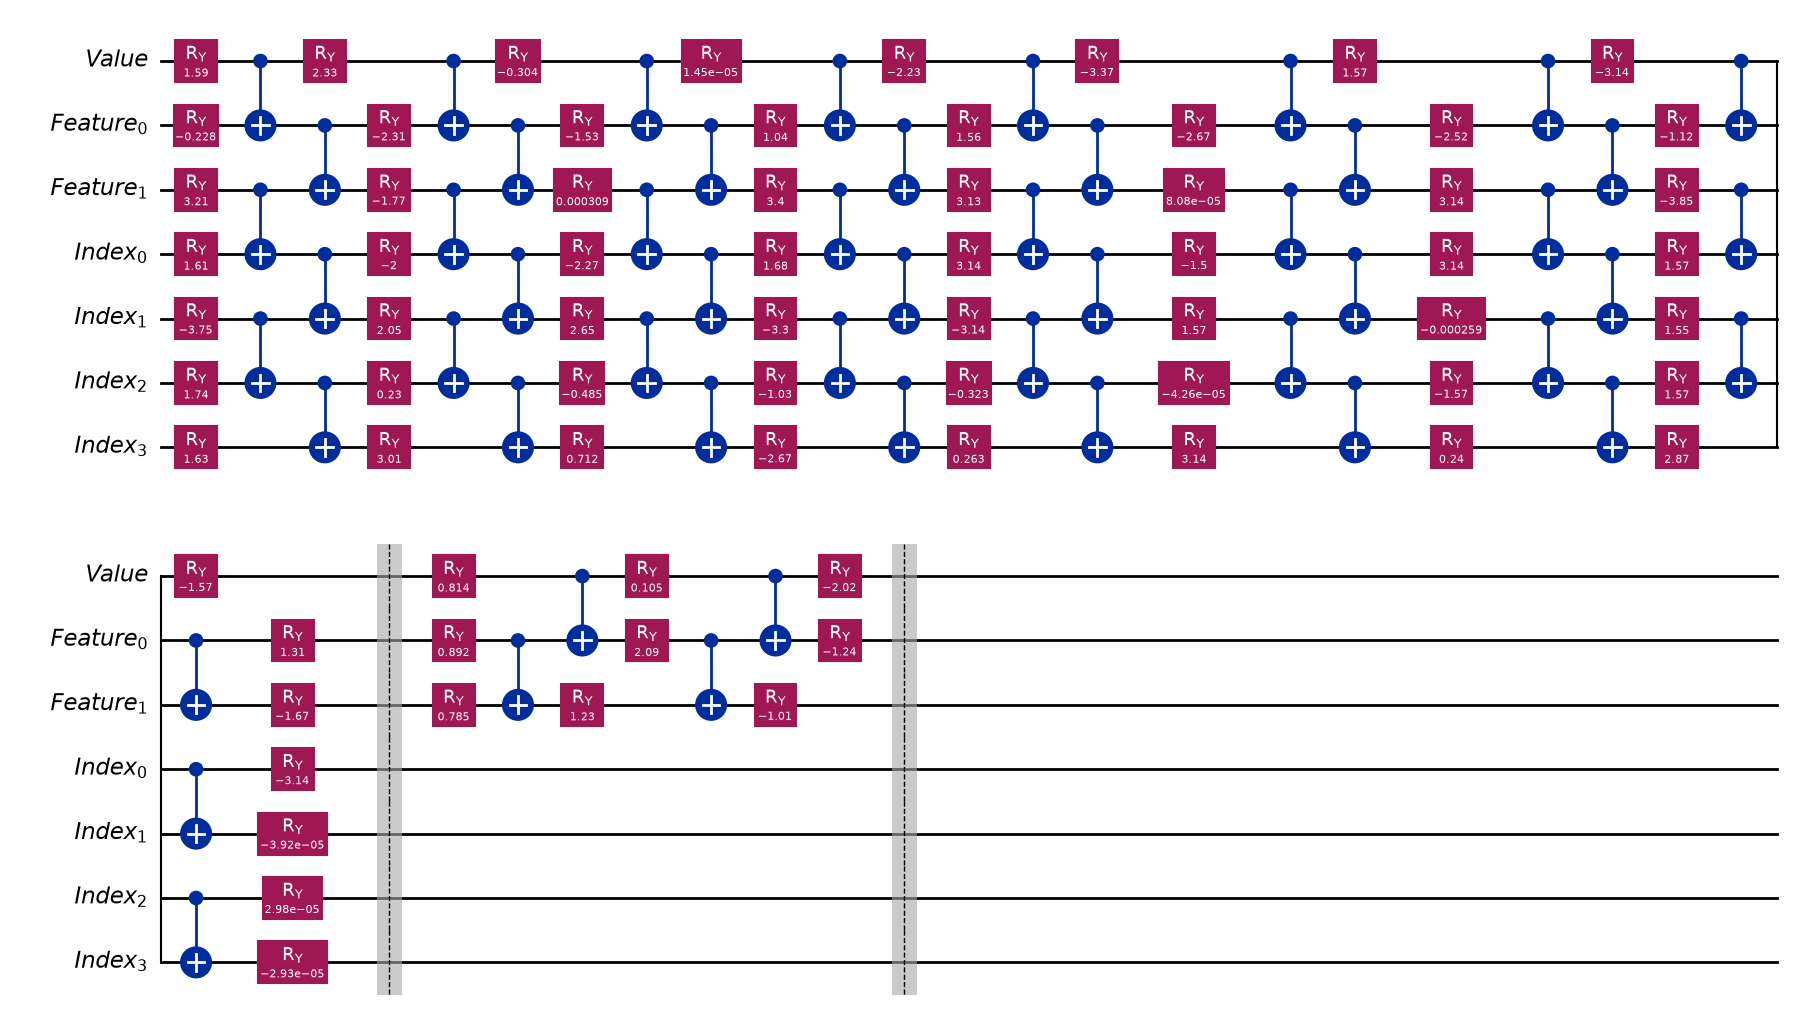

In [19]:
display(qc.draw("mpl"))

# <u>**Part 2: Use Grover Search for Image Matching**</u>

In [20]:
try:
    A_saved = load_parameters(scheme="FRQI", loss_function_type="FIDELITY")

    A_saved_parameters = A_saved["parameters"]
    A_saved_best_fidelity = A_saved["fidelity"]

    print(f"Loaded saved dataset encoder. Fidelity = {A_saved_best_fidelity:.3f}")

except (ValueError, KeyError, OSError) as e:
    print(f"Could not reuse saved dataset enocder. Train again.")

Loaded saved dataset encoder. Fidelity = 0.992


In [21]:
A_saved_parameters

array([ 1.58609957e+00, -2.27574416e-01,  3.21353912e+00,  1.60958033e+00,
       -3.74935787e+00,  1.74390525e+00,  1.62805042e+00,  2.33034645e+00,
       -2.31240258e+00, -1.77421663e+00, -1.99713242e+00,  2.04710865e+00,
        2.30006556e-01,  3.01022153e+00, -3.04404904e-01, -1.53443570e+00,
        3.08570551e-04, -2.27293484e+00,  2.64871492e+00, -4.85090297e-01,
        7.12050611e-01,  1.44825954e-05,  1.03756077e+00,  3.40303202e+00,
        1.67924875e+00, -3.30216068e+00, -1.03466238e+00, -2.66869432e+00,
       -2.23473035e+00,  1.55656019e+00,  3.13310310e+00,  3.14159983e+00,
       -3.14160250e+00, -3.22896398e-01,  2.63120945e-01, -3.36880509e+00,
       -2.66730177e+00,  8.08333831e-05, -1.50360801e+00,  1.57092413e+00,
       -4.25707062e-05,  3.14162178e+00,  1.57090091e+00, -2.52241238e+00,
        3.14144983e+00,  3.14180383e+00, -2.59327507e-04, -1.57084454e+00,
        2.40144017e-01, -3.14140300e+00, -1.11549838e+00, -3.84592965e+00,
        1.57064866e+00,  

In [22]:
GS = GroverSearch()

## <u>**GS with FRQI scheme and FIDELITY cost function**</u>

Number of data elements =  16
Number of features =  4
Index qubits =  4
Data qubits =  2
Value qubits =  1
Total no of qubits =  7
Range of value qubits =  [0]
Range of feature qubits =  [1, 2]
Range of index qubits =  [3, 4, 5, 6]

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.07090020811668361+0j)
|0000001> : (0.07819993319383609+0j)
|0000010> : (0.06711671722821226+0j)
|0000011> : (-0.19207614028612743+0j)
|0000100> : (-0.039845626567146686+0j)
|0000101> : (0.04718218255248071+0j)
|0000110> : (1.2290531005143921e-05+0j)
|0000111> : (-0.0015444410371535855+0j)
|0001000> : (0.12218916995057615+0j)
|0001001> : (0.06996759741740519+0j)
|0001010> : (0.0257277972690492+0j)
|0001011> : (-0.11387033810944598+0j)
|0001100> : (-0.04312141815267681+0j)
|0001101> : (0.12854951258234343+0j)
|0001110> : (-0.055251922269341606+0j)
|0001111> : (0.07976637372244073+0j)
|0010000> : (0.13087214029725133+0j)
|0010001> : (0.04792105911964145+0j)
|0010010> : (0.058804921251110746+0j)
|0010011> : (-0.12010815898990022+0j)
|0010100> : (-0.08301849175971913+0j)
|0010101> : (0.025957144473622126+0j)
|0010110> : (0.042440140172171084+0j)
|0010111> : (-0.143412279016705+0j)
|0011000> : (0.19209095448071822+0j)
|0011001> : (0.03905337744621

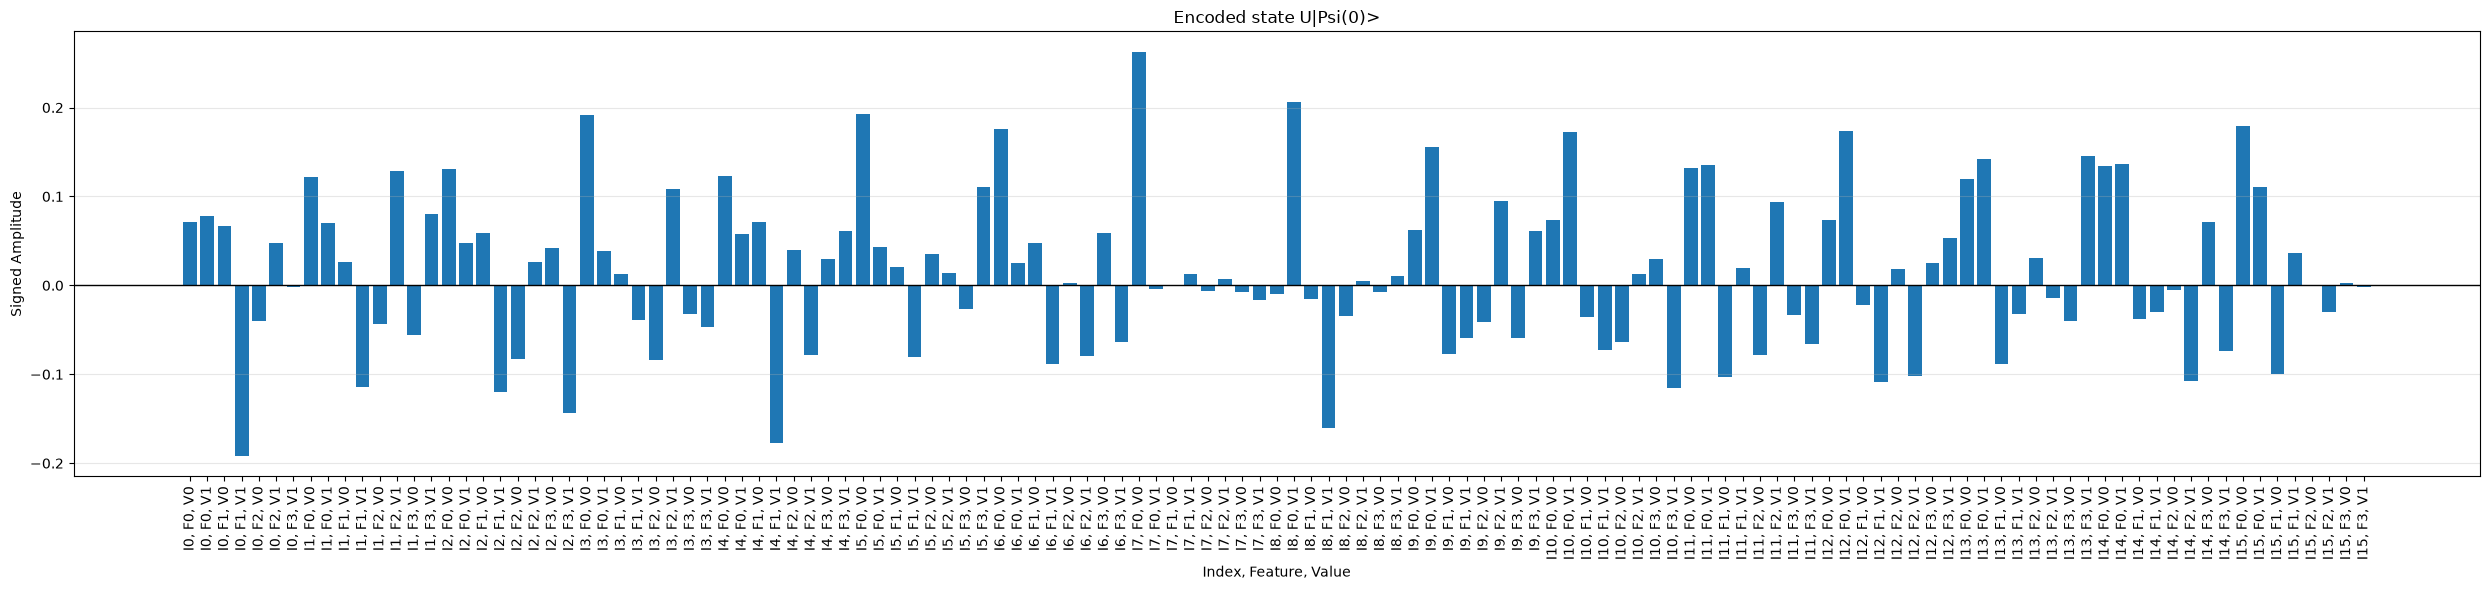


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


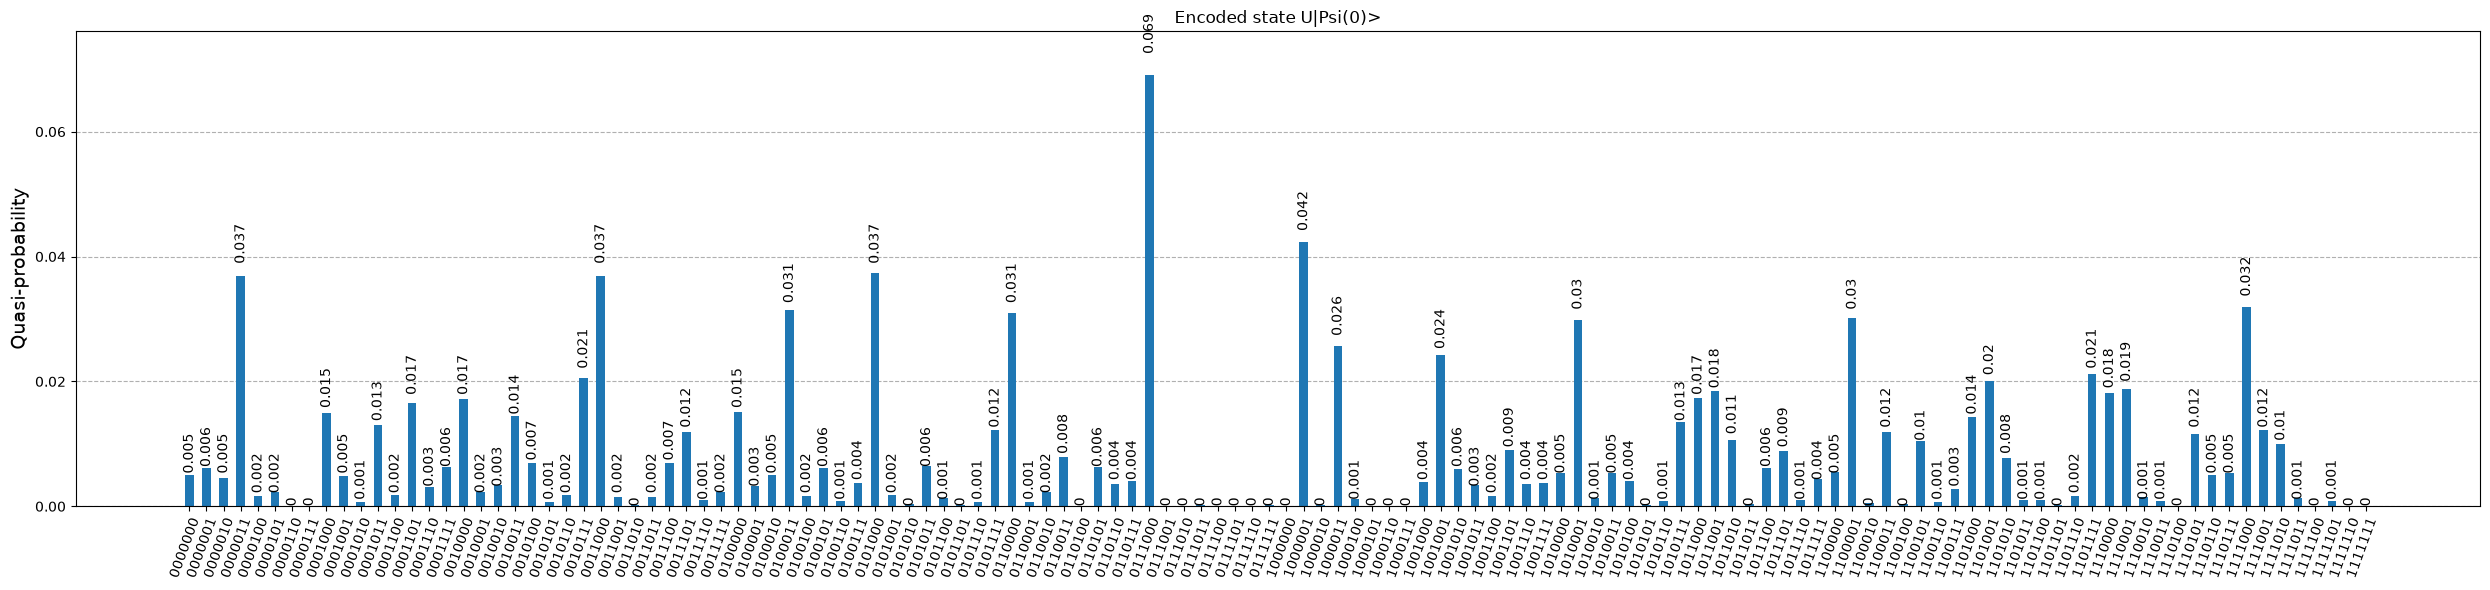

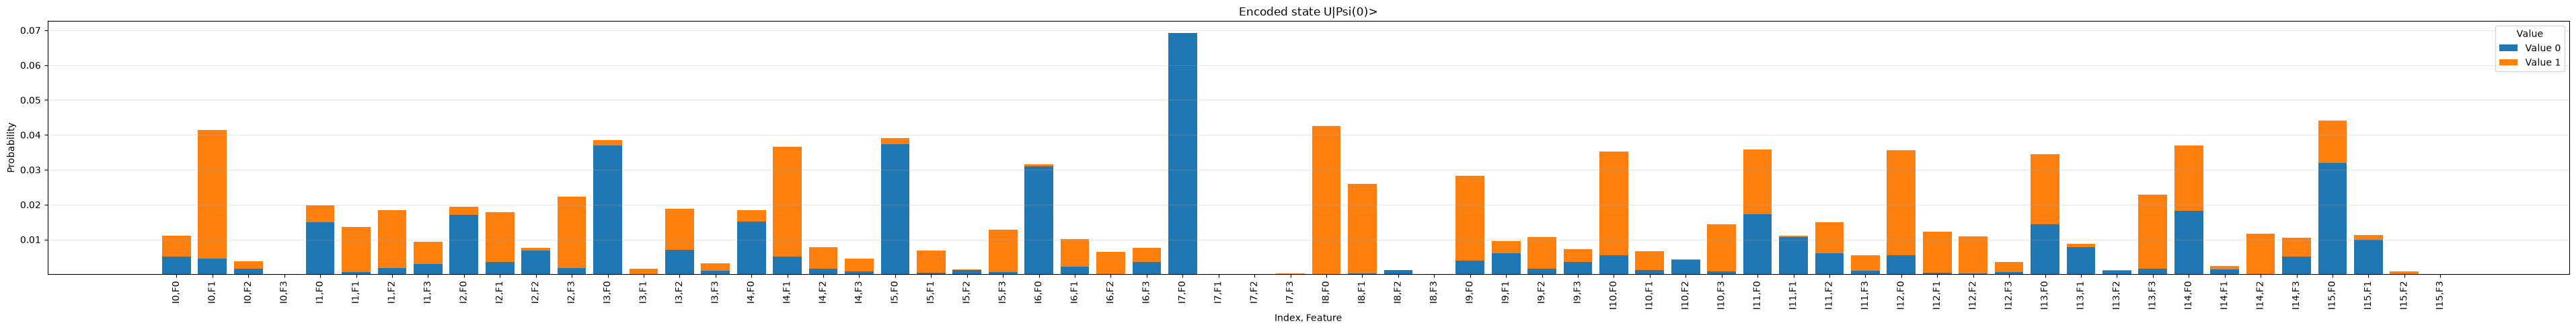


Encoded state U|Psi(0)>
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.071                   +0.078                   
0                        1                        +0.067                   -0.192                   
0                        2                        -0.040                   +0.047                   
0                        3                        +0.000                   -0.002                   
1                        0                        +0.122                   +0.070                   
1                        1                        +0.026                   -0.114                   
1                        2                        -0.043                   +0.129                   
1                        3                        -0.055          

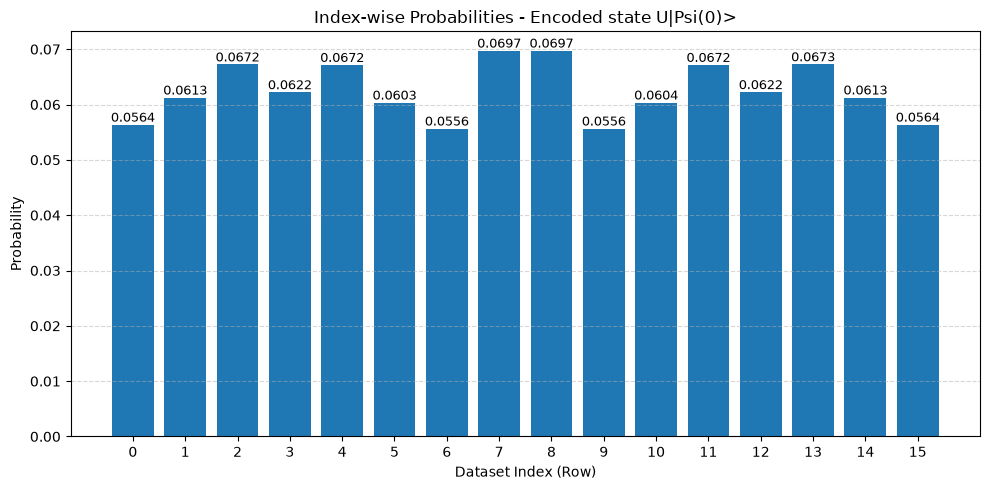




GROVER ITERATION 1


> Oracle: 

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (-0.0709002081166836+0j)
|0000001> : (0.07819993319383607+0j)
|0000010> : (0.06711671722821225+0j)
|0000011> : (-0.1920761402861274+0j)
|0000100> : (-0.03984562656714667+0j)
|0000101> : (0.0471821825524807+0j)
|0000110> : (1.2290531005140767e-05+0j)
|0000111> : (-0.0015444410371535935+0j)
|0001000> : (-0.12218916995057613+0j)
|0001001> : (0.06996759741740517+0j)
|0001010> : (0.025727797269049196+0j)
|0001011> : (-0.11387033810944597+0j)
|0001100> : (-0.04312141815267681+0j)
|0001101> : (0.1285495125823434+0j)
|0001110> : (-0.0552519222693416+0j)
|0001111> : (0.07976637372244072+0j)
|0010000> : (-0.1308721402972513+0j)
|0010001> : (0.047921059119641445+0j)
|0010010> : (0.05880492125111073+0j)
|0010011> : (-0.12010815898990021+0j)
|0010100> : (-0.08301849175971912+0j)
|0010101> : (0.025957144473622122+0j)
|0010110> : (0.04244014017217108+0j)
|0010111> : (-0.14341227901670497+0j)
|0011000> : (-0.19209095448071817+0j)
|0011001> : (0.039053377446217

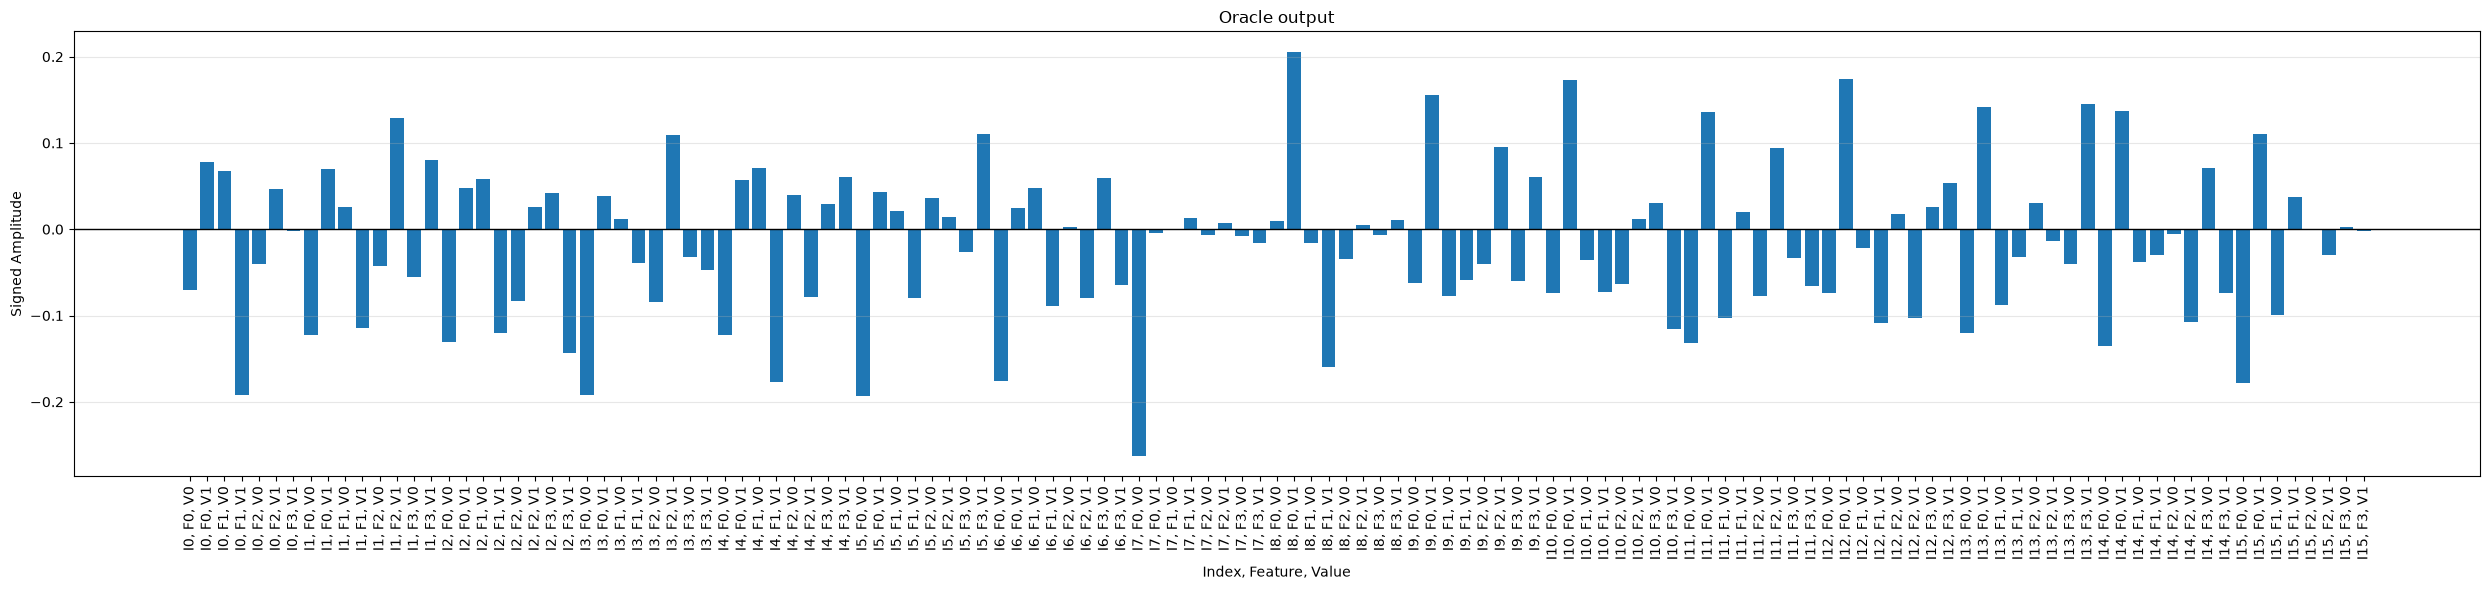


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


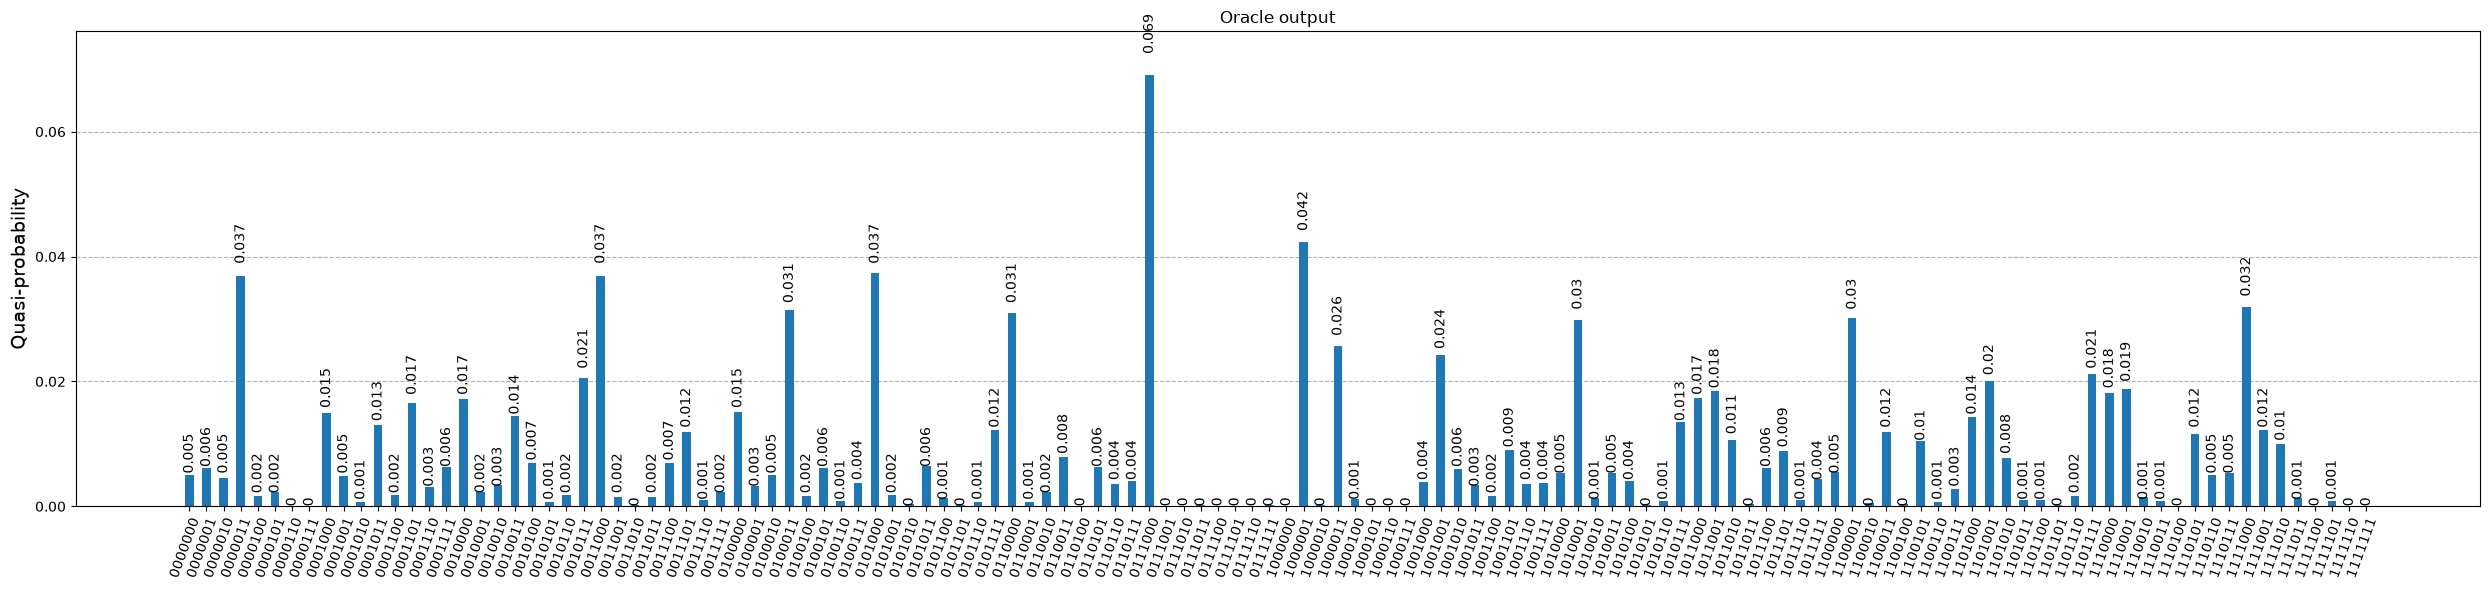

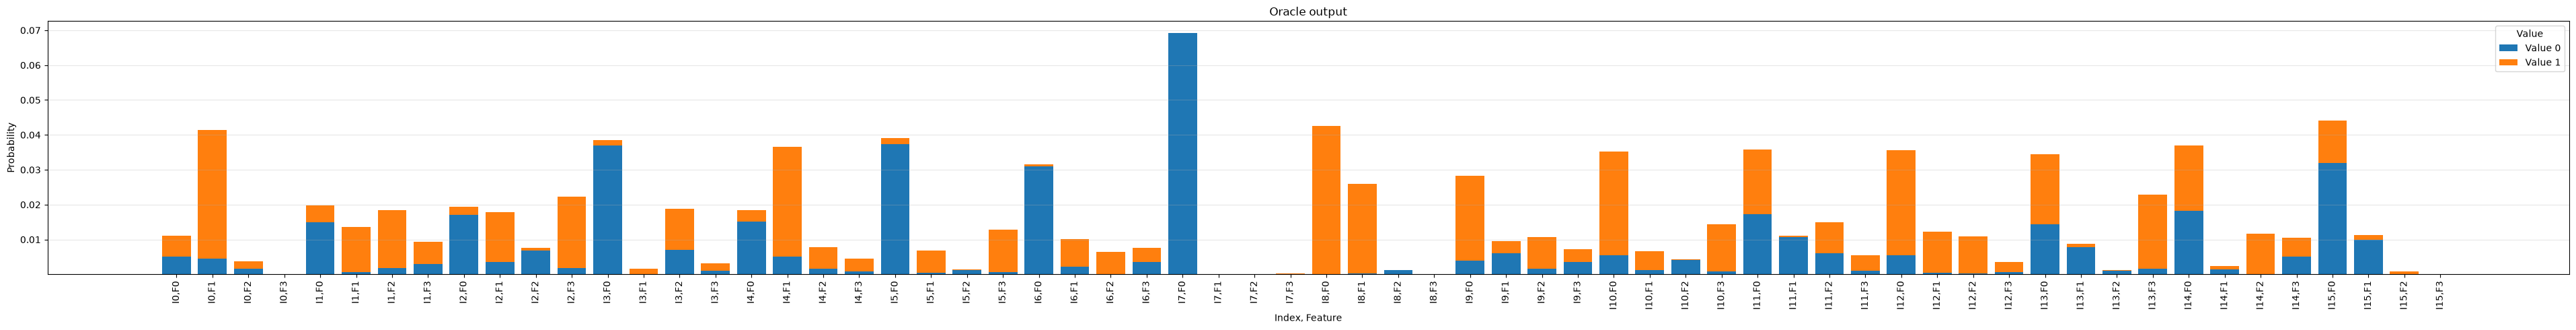


Oracle output
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        -0.071                   +0.078                   
0                        1                        +0.067                   -0.192                   
0                        2                        -0.040                   +0.047                   
0                        3                        +0.000                   -0.002                   
1                        0                        -0.122                   +0.070                   
1                        1                        +0.026                   -0.114                   
1                        2                        -0.043                   +0.129                   
1                        3                        -0.055                   +

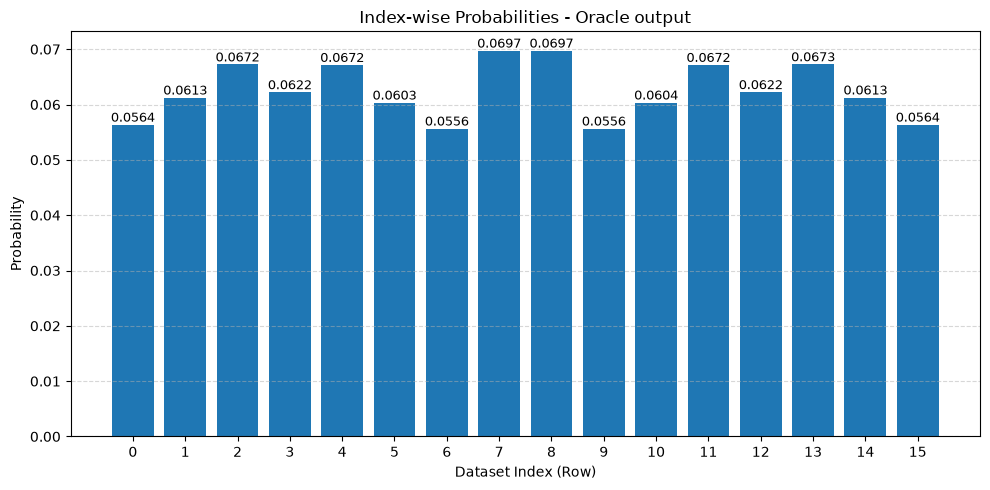



> Diffuser: 
Applying inverse of U...

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (-0.1210731006888945-1.0676486986644733e-17j)
|0000001> : (0.02286135307526493+1.3228539254563845e-17j)
|0000010> : (0.01962123121005213-2.775333640189564e-17j)
|0000011> : (-0.056152483526180595+2.2654440780420372e-17j)
|0000100> : (-0.011648666440657564+4.914089409859118e-17j)
|0000101> : (0.013793471300291267-2.0446115431325605e-17j)
|0000111> : (-0.0004515094887201856-1.2814590548837028e-17j)
|0001000> : (-0.2086569570031683-5.739794214213218e-17j)
|0001001> : (0.020454671545849595-1.2805872676189318e-18j)
|0001010> : (0.007521390788898114+1.276190680135685e-17j)
|0001011> : (-0.033289414683605696+8.498730040644e-17j)
|0001100> : (-0.012606327463872996+1.667525173041305e-17j)
|0001101> : (0.03758079674459146-4.075146007236021e-17j)
|0001110> : (-0.016152618697967032-1.2206248921335556e-17j)
|0001111> : (0.02331929400351459-4.225715949362454e-17j)
|0010000> : (-0.2234844754405127-4.6190800806255574e-18j)
|0010001> : (0.014009478109901038-6.0

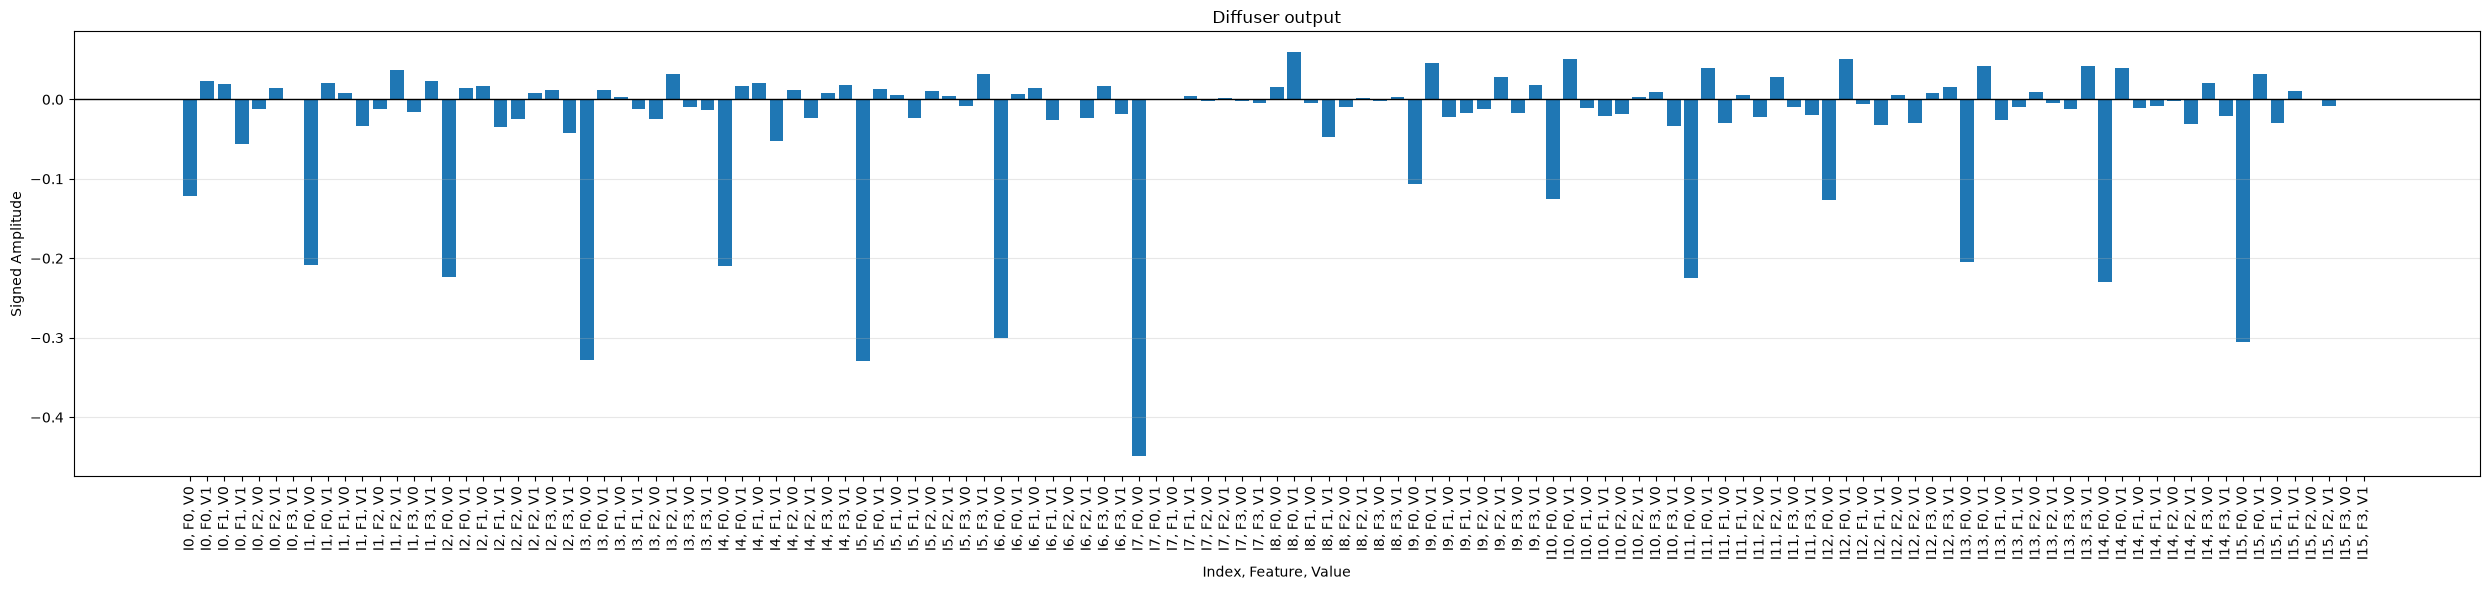


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


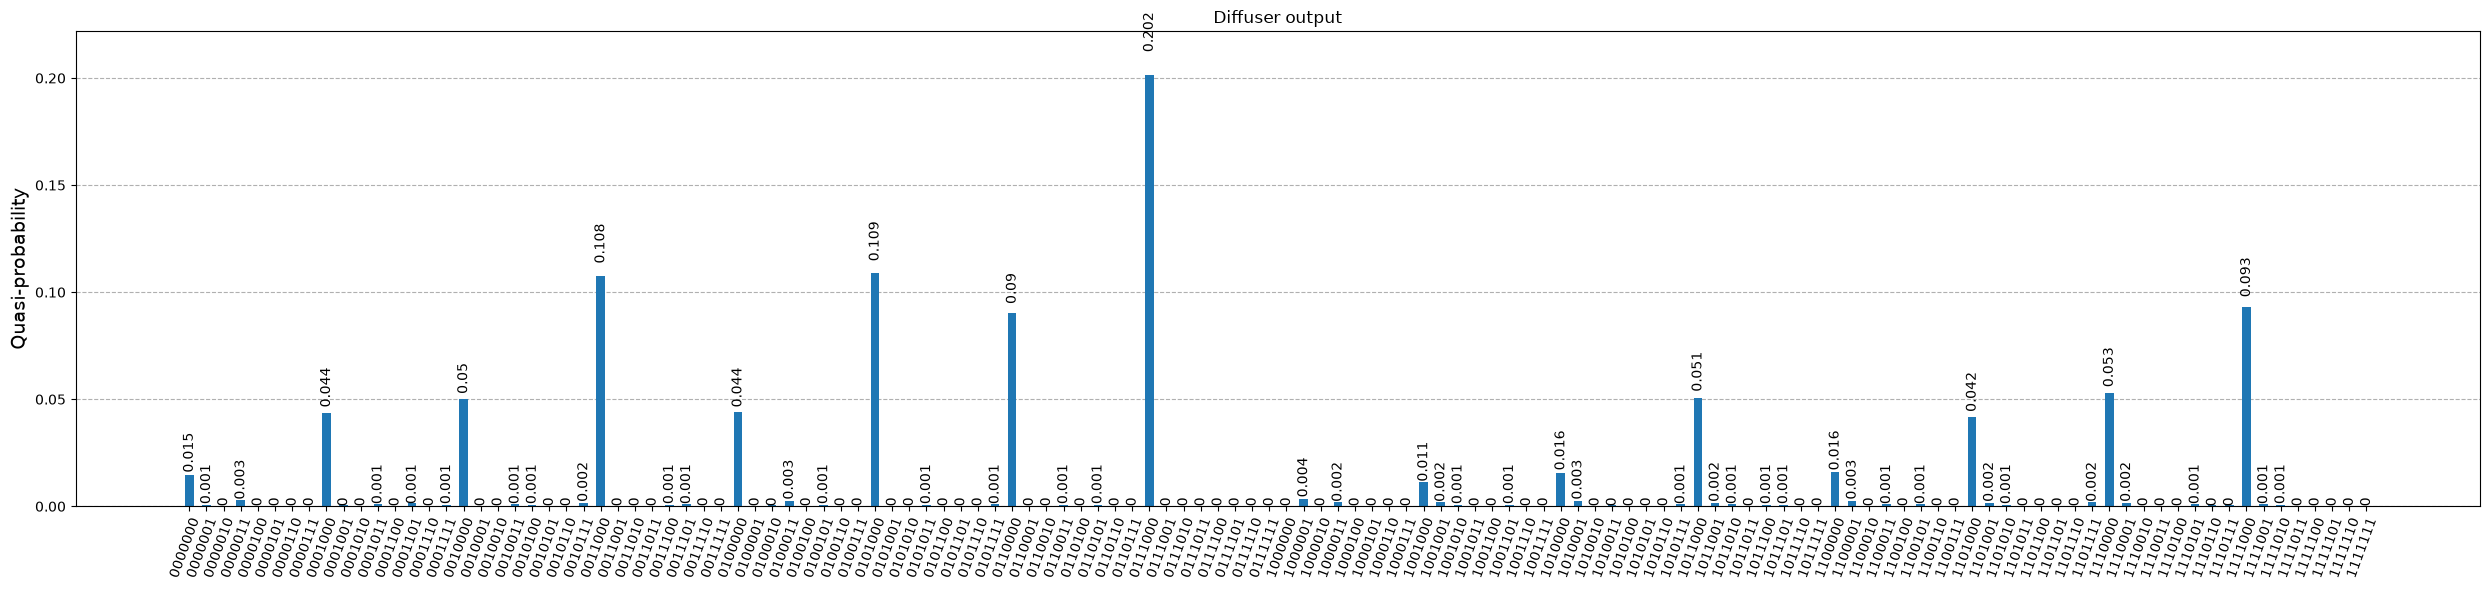

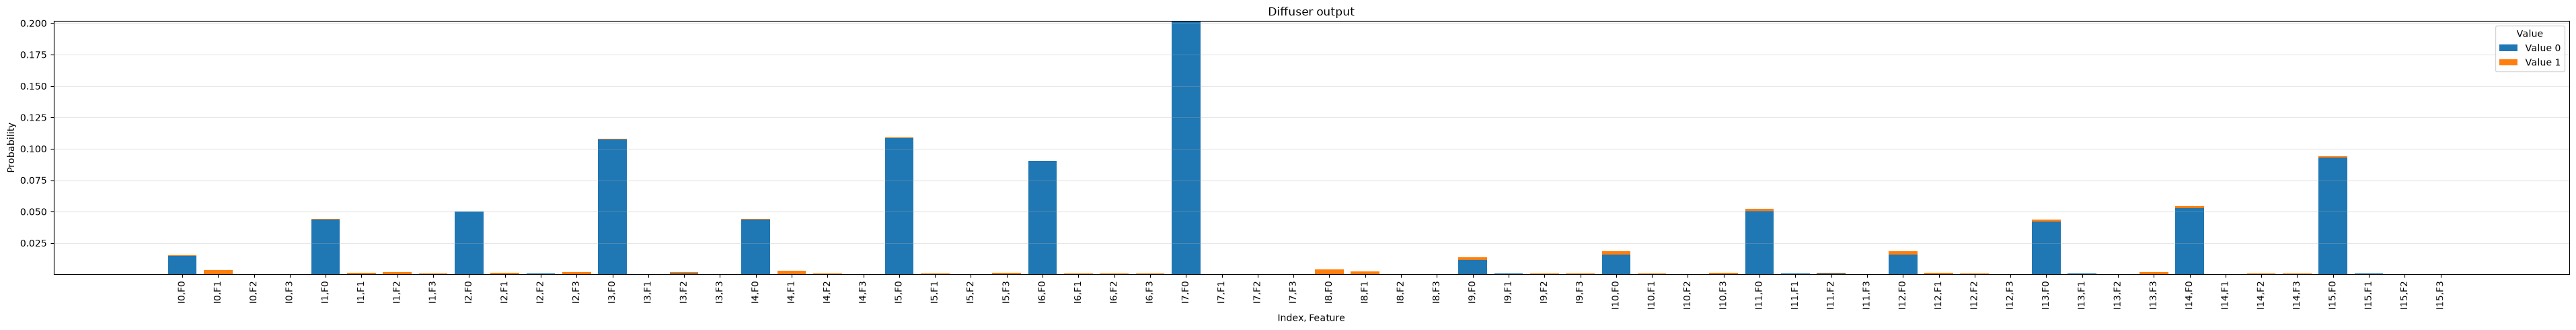


Diffuser output
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        -0.121                   +0.023                   
0                        1                        +0.020                   -0.056                   
0                        2                        -0.012                   +0.014                   
0                        3                        +0.000                   -0.000                   
1                        0                        -0.209                   +0.020                   
1                        1                        +0.008                   -0.033                   
1                        2                        -0.013                   +0.038                   
1                        3                        -0.016                  

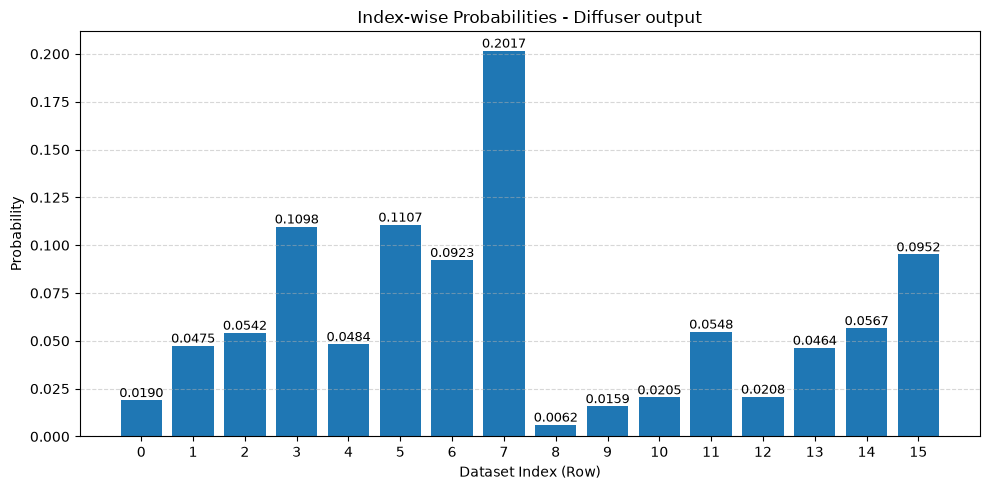


FINAL MEASUREMENT

Index measurement results for (2000) shots:
{'1010': 39, '0000': 40, '0010': 101, '1001': 31, '1011': 110, '0001': 93, '0011': 219, '0111': 416, '1101': 102, '1111': 197, '0101': 215, '1000': 6, '1110': 101, '0110': 188, '1100': 45, '0100': 97}


In [23]:
GS.run(dataset=dataset, query=query,
    A_parameters=A_parameters, B_parameters=B_parameters_frqi_fidelity,
    depth_A=pqc_depth_for_dataset_encoder, depth_B=pqc_depth_for_query_encoder,
    num_of_iter=1, scheme="FRQI"
)

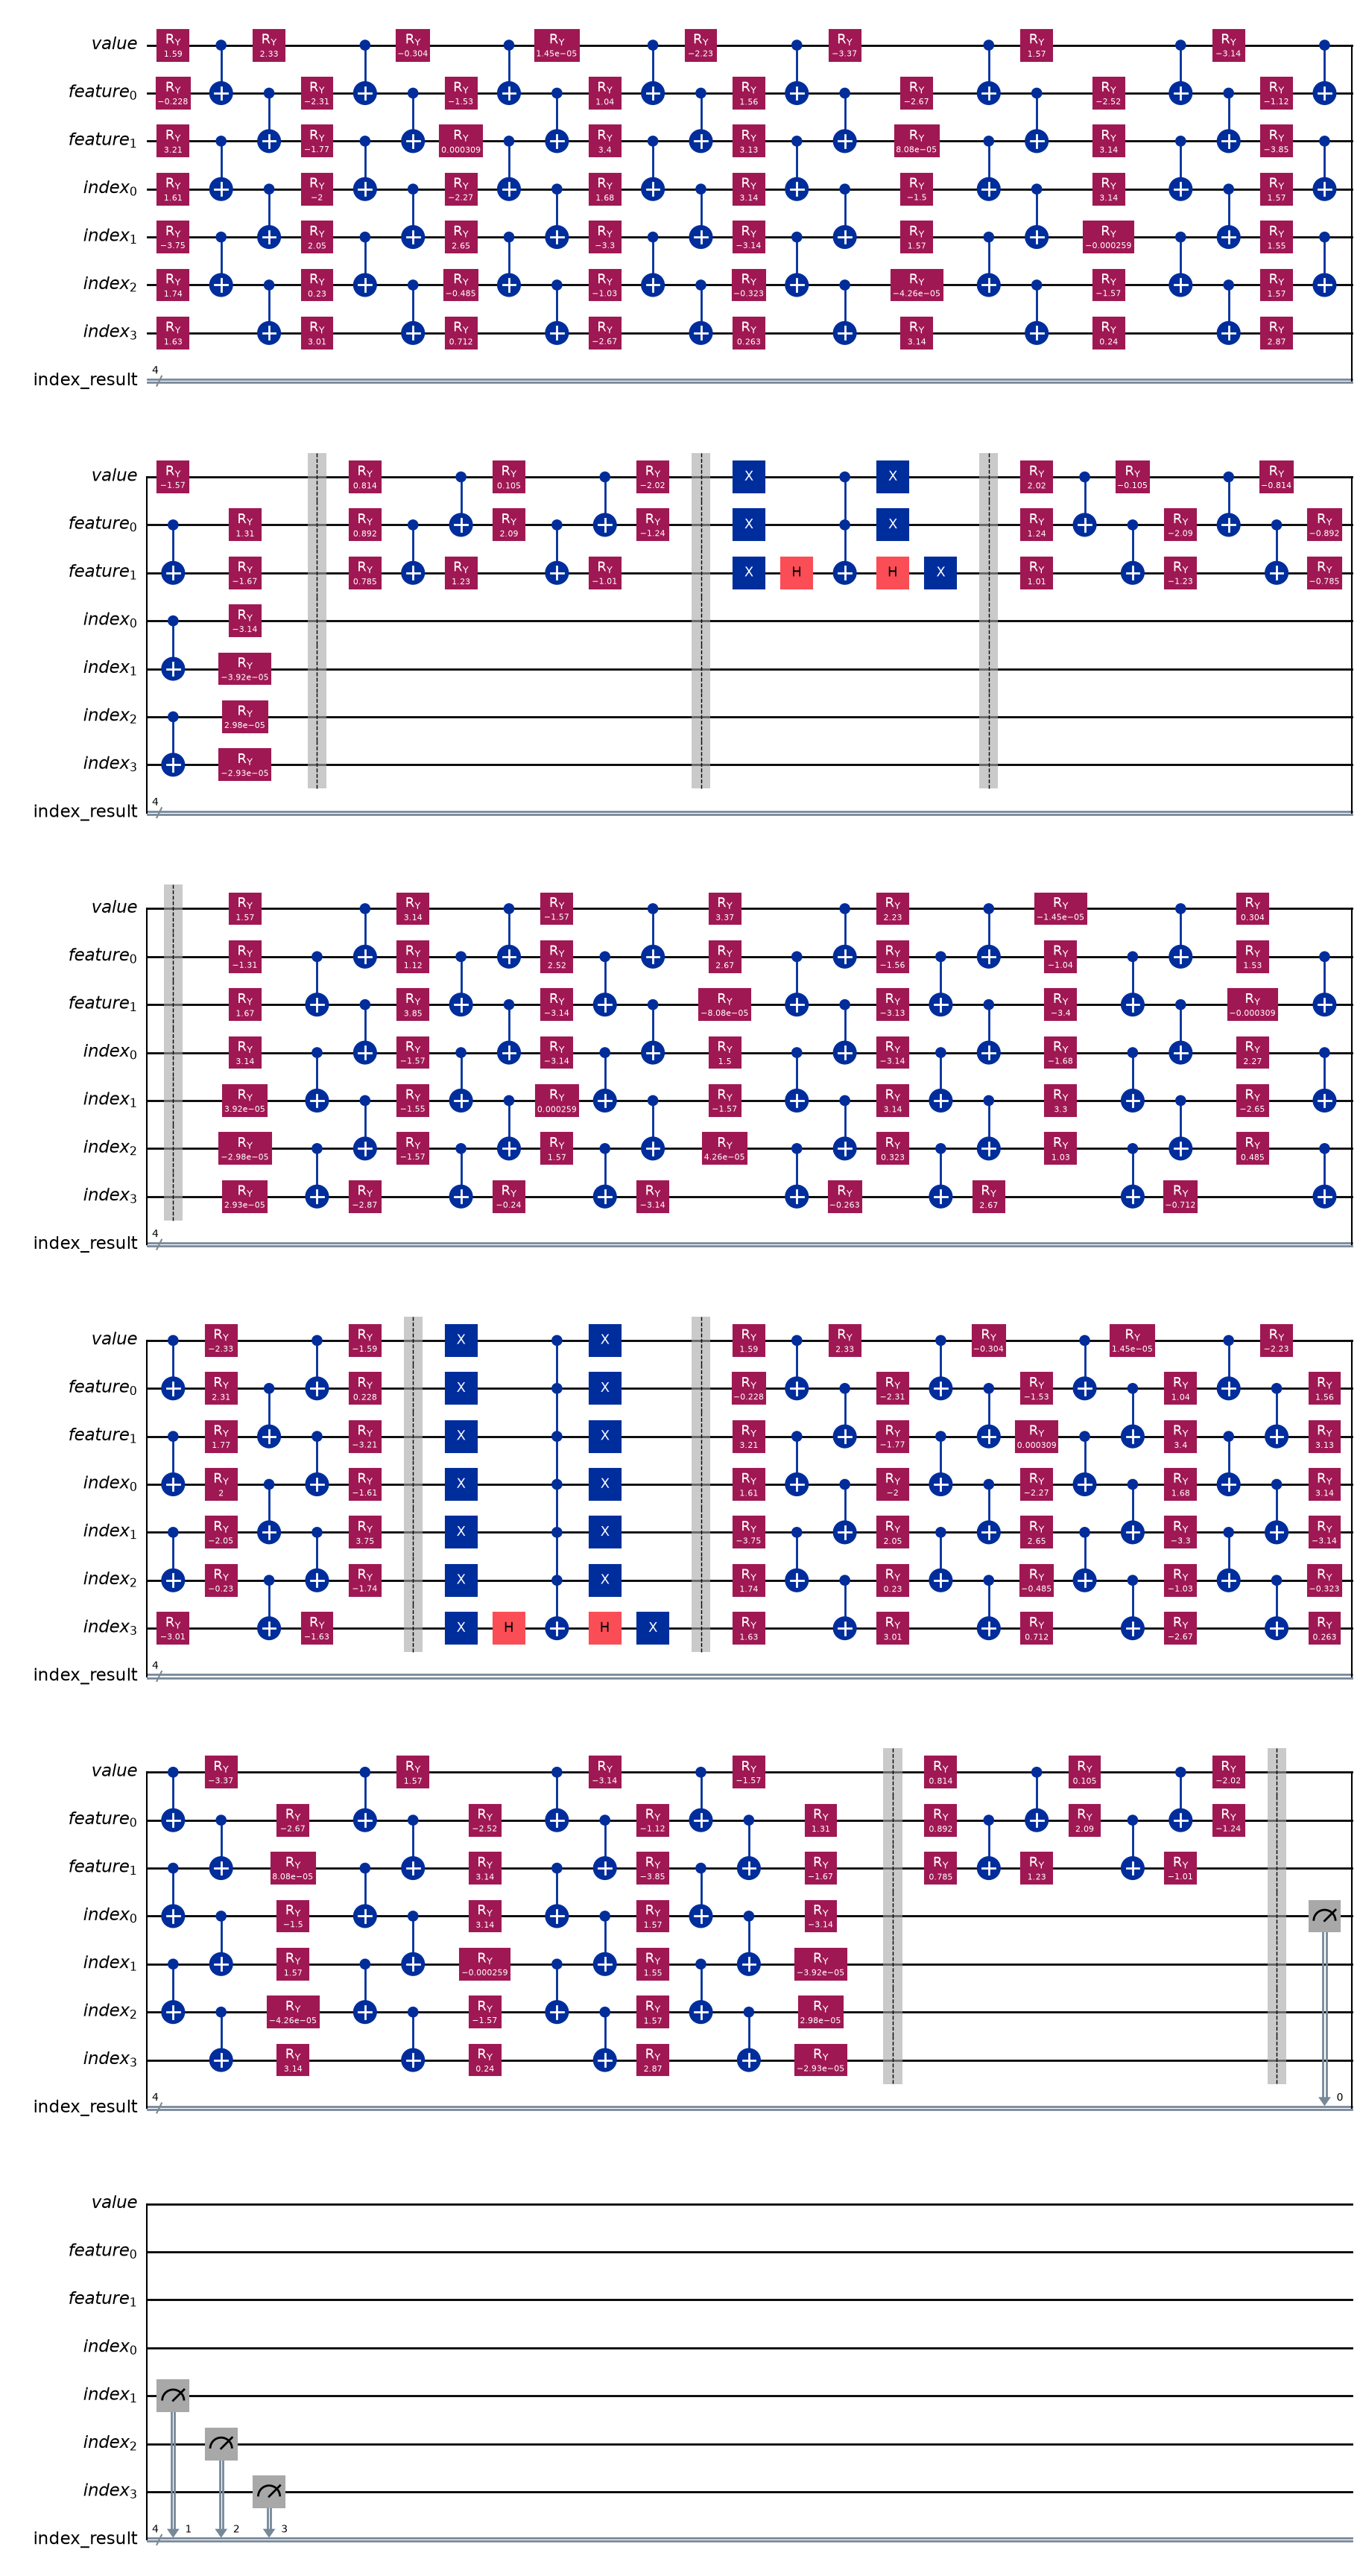

In [24]:
GS.draw_circuit()

In [25]:
GS.analysis()

REGISTER ANALYSIS
Dataset size (N): 16
Index qubits: 4
Data qubits: 2
Total qubits: 7
Classical bits: 4

CIRCUIT ANALYSIS
Circuit width: 11
Circuit size: 402
Circuit depth/layers: 107

OPERATION COUNT
OrderedDict({'ry': 216, 'cx': 156, 'x': 20, 'barrier': 8, 'h': 4, 'measure': 4, 'ccx': 1, 'mcx': 1})
